# EMG Signal Processing to Feature Matrix
### An Interactive Step-by-Step Coding Guide

---

## What This Notebook Teaches You

This notebook walks you through the **entire journey from raw EMG signal to feature matrix** -- the structured numerical table that machine learning classifiers use to predict gestures.

By the end of this notebook you will be able to:

- Generate realistic simulated EMG signals
- Understand what each NumPy and SciPy function actually does
- Apply bandpass filtering to remove noise
- Rectify and smooth the EMG envelope
- Normalize signals across channels
- Split signals into overlapping windows
- Extract five core EMG features from each window
- Assemble a complete feature matrix ready for a classifier
- Visualize and inspect every step of the pipeline

---

## How to Use This Notebook

Each section follows this pattern:

1. **Concept explanation** -- what we are doing and why
2. **Math intuition** -- what the math means in plain language
3. **Syntax lesson** -- explaining the Python/NumPy/SciPy syntax before you use it
4. **Try it yourself** -- a small coding task for you to attempt
5. **Full solution with line-by-line comments**

Look for these markers throughout the notebook:

- `# YOUR CODE HERE` -- cells where you write your own solution first
- `# SOLUTION` -- cells with the complete solution and explanation
- `# RESEARCH NOTE` -- connections to real EMG research
- `# SYNTAX LESSON` -- focused explanation of a Python concept

---

> **Before running this notebook:** Make sure you have installed the required libraries.
> Open a terminal and run: `pip install numpy scipy matplotlib pandas scikit-learn`
>
> Then restart your Jupyter kernel before running any cells.


---
## Section 0: Setup and Imports

Every Python script or notebook begins with imports. These lines tell Python which external libraries to load.

Think of imports like loading tools onto your workbench before you start a project. You would not wait until the middle of building a chair to go find a hammer.

### What Each Import Does

| Import | What it is | Why we need it |
|--------|-----------|----------------|
| `numpy as np` | Numerical array library | Fast math on arrays of numbers (your signal IS an array) |
| `scipy.signal` | Signal processing tools | Filters, FFT utilities, windowing functions |
| `scipy.fft` | Fast Fourier Transform | Converting time-domain signals to frequency domain |
| `matplotlib.pyplot as plt` | Plotting library | Visualizing signals, features, results |
| `pandas as pd` | Data table library | Organizing feature matrices with labels |
| `warnings` | Python built-in | Suppressing non-critical warnings |

### The `as` keyword
When you write `import numpy as np`, you are giving the library a shorter nickname.
Instead of typing `numpy.array([1,2,3])` every time, you type `np.array([1,2,3])`.
This is universal convention -- you will see `np`, `plt`, and `pd` in almost every data science codebase.

In [1]:
# =============================================================================
# SECTION 0: IMPORTS
# Run this cell first. If you get an ImportError, install the missing package.
# =============================================================================

import numpy as np                    # Numerical computing -- arrays, math
import scipy.signal as signal         # Signal processing -- filters, tools
import scipy.fft as fft               # Fast Fourier Transform
import matplotlib.pyplot as plt       # Plotting
import matplotlib.gridspec as gridspec # Advanced subplot layouts
import pandas as pd                   # DataFrames for feature matrices
import warnings
warnings.filterwarnings('ignore')     # Suppress minor warnings for cleaner output

# -----------------------------------------------------------------------
# MATPLOTLIB STYLE SETTINGS
# These lines control the appearance of all your plots in this notebook.
# You do not need to memorize these -- just know they make plots look clean.
# -----------------------------------------------------------------------
plt.rcParams['figure.dpi'] = 100          # Resolution of plots (dots per inch)
plt.rcParams['font.size'] = 11            # Default font size
plt.rcParams['axes.titlesize'] = 13       # Title font size
plt.rcParams['axes.labelsize'] = 11       # Axis label font size
plt.rcParams['lines.linewidth'] = 1.2     # Default line thickness
plt.rcParams['figure.facecolor'] = 'white' # White background

# -----------------------------------------------------------------------
# GLOBAL PARAMETERS
# Define these once here. Use them everywhere below.
# Never hard-code numbers like 1000 or 4 in the middle of your code.
# Always use named variables so your code stays readable and flexible.
# -----------------------------------------------------------------------
FS = 1000          # Sampling rate in Hz (1000 samples per second)
N_CHANNELS = 8     # Number of EMG electrodes
RANDOM_SEED = 42   # For reproducibility: same results every run

np.random.seed(RANDOM_SEED)

print("All imports successful!")
print(f"NumPy version:      {np.__version__}")
print(f"SciPy version:      {__import__('scipy').__version__}")
print(f"Matplotlib version: {__import__('matplotlib').__version__}")
print(f"Pandas version:     {pd.__version__}")
print(f"\nGlobal config:")
print(f"  Sampling rate:    {FS} Hz")
print(f"  EMG channels:     {N_CHANNELS}")
print(f"  Random seed:      {RANDOM_SEED}")

All imports successful!
NumPy version:      2.4.4
SciPy version:      1.17.1
Matplotlib version: 3.10.9
Pandas version:     3.0.2

Global config:
  Sampling rate:    1000 Hz
  EMG channels:     8
  Random seed:      42


---
## Section 1: Generating Realistic Simulated EMG

### Why Simulate Data?

Before you have access to a real EMG armband, you need data to work with. Simulated data also has a major advantage: **you know the ground truth**. You know exactly when the muscle is "active", what the noise level is, and what the signal should look like after processing. This makes it perfect for learning and debugging.

### What Real EMG Looks Like

Real surface EMG during a muscle contraction looks like **band-limited noise** -- random oscillations happening mostly between 20 Hz and 500 Hz. The key properties are:

1. **Zero-mean**: the signal oscillates above and below zero
2. **Amplitude-modulated**: the signal gets larger when the muscle is more active
3. **Stochastic**: it looks random because it is the sum of thousands of tiny motor unit action potentials
4. **Multi-channel**: an armband captures this from 8 (or 16) positions around the forearm

### Our Simulation Strategy

We will generate signals for **5 gestures** (Rest, Hand Open, Hand Closed, Wrist Flexion, Wrist Extension), each with its own:
- Amplitude envelope (which muscles activate and how much)
- Spectral shape (filtered noise in the EMG frequency band)
- Per-channel activation pattern (different muscles face different electrodes)

This gives us labeled data we can use for the entire pipeline.

### Syntax Lesson: Functions in Python

We will define reusable **functions** using `def`. The structure is:

```python
def function_name(parameter1, parameter2, optional_param=default_value):
    """
    Docstring: explains what the function does, its parameters, and what it returns.
    """
    # code here
    return result
```

**Parameters with `=` have default values** and are optional when calling the function.
**Parameters without `=` are required.**

Good functions do one thing, have a docstring, and have clearly named parameters.

In [2]:
# =============================================================================
# SECTION 1A: HELPER FUNCTIONS FOR SIGNAL GENERATION
# =============================================================================

def sigmoid(x):
    """
    The logistic (sigmoid) function. Maps any real number to the range (0, 1).
    Used to create smooth transitions in our activation envelope.
    
    Formula: sigmoid(x) = 1 / (1 + e^(-x))
    
    Parameters
    ----------
    x : np.ndarray or float
        Input value(s)
    
    Returns
    -------
    np.ndarray or float
        Values between 0 and 1
    """
    return 1.0 / (1.0 + np.exp(-x))
    # np.exp(x) computes e^x for every element in x
    # When x is very negative: exp(-x) is huge, so sigmoid -> 0
    # When x is very positive: exp(-x) is tiny, so sigmoid -> 1
    # At x=0: sigmoid = 0.5


def smooth_activation_envelope(t, t_start, t_end, rise_time=0.08):
    """
    Creates a smooth on/off amplitude envelope using two sigmoids.
    Values are 0 (rest) before t_start, rise to 1 (active) between
    t_start and t_end, then fall back to 0 after t_end.
    
    Parameters
    ----------
    t         : np.ndarray -- time axis in seconds
    t_start   : float      -- when activation begins (seconds)
    t_end     : float      -- when activation ends (seconds)
    rise_time : float      -- controls transition sharpness (seconds)
                             smaller = sharper edges
    Returns
    -------
    envelope : np.ndarray -- values between 0 and 1, same length as t
    """
    # Rising edge: sigmoid centered at t_start
    # (t - t_start) / rise_time: shifts sigmoid to be centered at t_start
    # Dividing by rise_time controls how steep the slope is
    rising  = sigmoid((t - t_start) / rise_time)
    
    # Falling edge: reversed sigmoid centered at t_end
    # (t_end - t) flips the direction so it falls after t_end
    falling = sigmoid((t_end - t)   / rise_time)
    
    # Multiply: only high where BOTH are near 1 (i.e., between t_start and t_end)
    return rising * falling


def bandpass_filter_signal(raw_signal, fs, lowcut=20.0, highcut=450.0, order=4):
    """
    Apply a Butterworth bandpass filter to a signal.
    This keeps frequencies between lowcut and highcut, removing the rest.
    
    Parameters
    ----------
    raw_signal : np.ndarray  -- shape (n_samples,) or (n_samples, n_channels)
    fs         : float       -- sampling rate in Hz
    lowcut     : float       -- lower frequency cutoff in Hz (default 20 Hz)
    highcut    : float       -- upper frequency cutoff in Hz (default 450 Hz)
    order      : int         -- filter order (higher = steeper rolloff)
    
    Returns
    -------
    filtered : np.ndarray -- filtered signal, same shape as input
    """
    # Nyquist frequency = half the sampling rate
    # ALL frequency calculations in scipy.signal are normalized to Nyquist
    # So we divide our cutoff frequencies by Nyquist to get normalized values (0 to 1)
    nyquist = fs / 2.0
    low  = lowcut  / nyquist   # e.g., 20/500 = 0.04
    high = highcut / nyquist   # e.g., 450/500 = 0.90
    
    # Design the Butterworth filter coefficients
    # 'bandpass' means we keep frequencies BETWEEN low and high
    # Returns b (numerator) and a (denominator) coefficients
    b, a = signal.butter(order, [low, high], btype='bandpass')
    
    # Apply the filter using filtfilt (zero-phase: applies filter forward THEN backward)
    # This eliminates phase distortion -- the filtered signal lines up correctly in time
    # axis=0 means we filter along the time dimension (rows)
    filtered = signal.filtfilt(b, a, raw_signal, axis=0)
    
    return filtered


print("Helper functions defined.")
print("\nQuick test of sigmoid function:")
test_values = np.array([-10, -2, 0, 2, 10])
print(f"  Input:  {test_values}")
print(f"  Output: {sigmoid(test_values).round(4)}")
print("  (Should go from near 0 to near 1 with 0.5 in the middle)")

Helper functions defined.

Quick test of sigmoid function:
  Input:  [-10  -2   0   2  10]
  Output: [0.     0.1192 0.5    0.8808 1.    ]
  (Should go from near 0 to near 1 with 0.5 in the middle)


In [3]:
# =============================================================================
# SECTION 1B: GESTURE CONFIGURATION
# =============================================================================
#
# In a real EMG dataset, each gesture activates different muscles.
# Different muscles face different electrodes on the armband.
# We simulate this with a per-gesture "channel activation pattern".
#
# The pattern is an array of 8 values (one per channel).
# Values between 0 and 1 represent how strongly each channel responds.
# 0.0 = that muscle is not involved in this gesture
# 1.0 = that muscle is fully activated for this gesture
# Values in between = partial activation
#
# RESEARCH NOTE:
# In real research, this "activation pattern" is what makes gestures
# distinguishable. A classifier learns that certain channels are loud
# for "Hand Closed" and different channels are loud for "Wrist Flexion".
# If these patterns overlap too much, classification becomes difficult.
# This is related to the concept of "class separability" in feature space.

GESTURE_CONFIG = {
    # name: {
    #   'label':     integer class label (0, 1, 2, ...)
    #   'amplitude': peak EMG amplitude during activation (mV)
    #   'pattern':   8-channel activation weights (which muscles fire)
    # }
    'Rest': {
        'label': 0,
        'amplitude': 0.05,   # Very low amplitude during rest
        'pattern': np.array([0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1])
        # All channels quiet, small baseline noise
    },
    'Hand Open': {
        'label': 1,
        'amplitude': 0.8,
        'pattern': np.array([0.9, 0.8, 0.3, 0.2, 0.1, 0.2, 0.7, 0.8])
        # Extensor muscles (channels 0,1,6,7) more active
    },
    'Hand Closed': {
        'label': 2,
        'amplitude': 1.0,
        'pattern': np.array([0.2, 0.3, 0.8, 0.9, 0.8, 0.7, 0.2, 0.1])
        # Flexor muscles (channels 2,3,4,5) more active
    },
    'Wrist Flexion': {
        'label': 3,
        'amplitude': 0.7,
        'pattern': np.array([0.1, 0.2, 0.5, 0.8, 0.9, 0.6, 0.2, 0.1])
        # Deep flexors (channels 3,4,5) dominant
    },
    'Wrist Extension': {
        'label': 4,
        'amplitude': 0.7,
        'pattern': np.array([0.8, 0.9, 0.2, 0.1, 0.1, 0.2, 0.8, 0.7])
        # Extensor carpi muscles (channels 0,1,6,7) dominant
    }
}

GESTURE_NAMES = list(GESTURE_CONFIG.keys())
N_GESTURES    = len(GESTURE_NAMES)

print(f"Configured {N_GESTURES} gestures:")
for name, cfg in GESTURE_CONFIG.items():
    print(f"  Label {cfg['label']}: {name:20s} | amplitude={cfg['amplitude']:.2f} mV")

Configured 5 gestures:
  Label 0: Rest                 | amplitude=0.05 mV
  Label 1: Hand Open            | amplitude=0.80 mV
  Label 2: Hand Closed          | amplitude=1.00 mV
  Label 3: Wrist Flexion        | amplitude=0.70 mV
  Label 4: Wrist Extension      | amplitude=0.70 mV


In [4]:
# =============================================================================
# SECTION 1C: MAIN SIGNAL GENERATOR
# =============================================================================

def generate_emg_trial(
    gesture_name,
    fs=FS,
    duration=4.0,
    active_start=1.0,
    active_end=3.0,
    noise_floor=0.04,
    channel_noise_std=0.03,
    rng=None
):
    """
    Generate one trial of simulated multi-channel surface EMG.
    
    A 'trial' is one recording of a single gesture attempt:
    rest period --> gesture activation --> rest period.
    
    Parameters
    ----------
    gesture_name     : str   -- must be a key in GESTURE_CONFIG
    fs               : int   -- sampling rate in Hz
    duration         : float -- total trial duration in seconds
    active_start     : float -- when gesture activation begins (seconds)
    active_end       : float -- when gesture activation ends (seconds)
    noise_floor      : float -- baseline noise amplitude during rest
    channel_noise_std: float -- standard deviation of per-channel gain noise
                               (simulates variability between electrode contacts)
    rng              : np.random.Generator or None
                               random generator for reproducibility
    
    Returns
    -------
    t       : np.ndarray, shape (n_samples,)           -- time axis in seconds
    emg_raw : np.ndarray, shape (n_samples, n_channels) -- raw EMG in mV
    label   : int                                       -- integer class label
    """
    # Use default numpy random state if none provided
    if rng is None:
        rng = np.random.default_rng(RANDOM_SEED)
    
    config     = GESTURE_CONFIG[gesture_name]
    n_samples  = int(fs * duration)
    n_channels = len(config['pattern'])
    
    # ------------------------------------------------------------------
    # Step 1: Create time axis
    # linspace(start, stop, num, endpoint=False):
    #   Creates 'num' evenly spaced values in [start, stop)
    #   endpoint=False: do not include the final value
    #   This matches the convention that sample[k] is at time k/fs
    # ------------------------------------------------------------------
    t = np.linspace(0, duration, n_samples, endpoint=False)
    
    # ------------------------------------------------------------------
    # Step 2: Create the activation envelope
    # Values 0.0 (rest) to 1.0 (full activation)
    # ------------------------------------------------------------------
    envelope = smooth_activation_envelope(t, active_start, active_end)
    
    # ------------------------------------------------------------------
    # Step 3: Compute instantaneous amplitude
    # During rest: amplitude = noise_floor (small)
    # During activation: amplitude = noise_floor + gesture_amplitude
    # The envelope smoothly interpolates between these two states
    # ------------------------------------------------------------------
    peak_amp       = config['amplitude']   # e.g., 1.0 mV for Hand Closed
    inst_amplitude = noise_floor + (peak_amp - noise_floor) * envelope
    # inst_amplitude shape: (n_samples,)
    # Example at t=0.5s (rest):     0.04 + (1.0 - 0.04)*0.0 = 0.04 mV
    # Example at t=2.0s (active):   0.04 + (1.0 - 0.04)*1.0 = 1.00 mV
    
    # ------------------------------------------------------------------
    # Step 4: Generate white noise and scale by amplitude
    # rng.standard_normal(shape): draws samples from N(0,1)
    # We generate all channels at once: shape = (n_samples, n_channels)
    # ------------------------------------------------------------------
    white_noise = rng.standard_normal((n_samples, n_channels))
    
    # Multiply each time point's noise by the instantaneous amplitude
    # inst_amplitude has shape (n_samples,)
    # To multiply with (n_samples, n_channels), we add a new axis:
    # inst_amplitude[:, np.newaxis] -> shape (n_samples, 1)
    # NumPy broadcasting then scales each of the 8 columns identically
    emg_scaled = white_noise * inst_amplitude[:, np.newaxis]
    
    # ------------------------------------------------------------------
    # Step 5: Apply per-channel activation pattern
    # Different muscles (channels) activate differently for each gesture
    # pattern shape: (n_channels,) = (8,)
    # emg_scaled shape: (n_samples, n_channels)
    # Multiplying: each column gets scaled by the corresponding pattern value
    # pattern[np.newaxis, :] -> shape (1, 8) for broadcasting
    # ------------------------------------------------------------------
    channel_pattern = config['pattern'][np.newaxis, :]  # (1, 8)
    emg_patterned   = emg_scaled * channel_pattern       # (n_samples, 8)
    
    # ------------------------------------------------------------------
    # Step 6: Add per-channel contact noise
    # Real electrodes have variability: different skin-electrode impedance,
    # different pressure, slight differences in gel or sweat.
    # We simulate this as a small random gain per channel.
    # rng.normal(mean, std, size): draws from N(mean, std)
    # We want gains near 1.0 with small variation
    # ------------------------------------------------------------------
    contact_noise = rng.normal(1.0, channel_noise_std, size=n_channels)
    emg_raw       = emg_patterned * contact_noise[np.newaxis, :]  # (n_samples, 8)
    
    # ------------------------------------------------------------------
    # Step 7: Bandpass filter to EMG frequency range (20-450 Hz)
    # White noise has energy at ALL frequencies.
    # Real EMG has energy mostly in 20-500 Hz.
    # Filtering makes our simulation spectral properties match real EMG.
    # ------------------------------------------------------------------
    emg_raw = bandpass_filter_signal(emg_raw, fs, lowcut=20.0, highcut=450.0)
    
    return t, emg_raw, config['label']


# ------------------------------------------------------------------
# Quick test: generate one trial of "Hand Closed"
# ------------------------------------------------------------------
t_test, emg_test, label_test = generate_emg_trial('Hand Closed')

print("Trial generated successfully!")
print(f"  Time axis shape:  {t_test.shape}   -- {len(t_test)} samples")
print(f"  EMG array shape:  {emg_test.shape}  -- (samples x channels)")
print(f"  Label:            {label_test}       -- (2 = Hand Closed)")
print(f"  Time range:       {t_test[0]:.3f}s to {t_test[-1]:.3f}s")
print(f"  Signal amplitude: min={emg_test.min():.4f} mV, max={emg_test.max():.4f} mV")

Trial generated successfully!
  Time axis shape:  (4000,)   -- 4000 samples
  EMG array shape:  (4000, 8)  -- (samples x channels)
  Label:            2       -- (2 = Hand Closed)
  Time range:       0.000s to 3.999s
  Signal amplitude: min=-3.3244 mV, max=2.9122 mV


In [5]:
# =============================================================================
# SECTION 1D: GENERATE A FULL DATASET
# Multiple trials per gesture, different random states
# =============================================================================
#
# In a real experiment, a participant would perform each gesture
# multiple times ("trials") while being recorded.
# We simulate N_TRIALS_PER_GESTURE for each of our 5 gestures.
#
# SYNTAX LESSON: Lists and list appending
# We collect results in lists then stack them into arrays.
#   my_list = []           -- create empty list
#   my_list.append(item)   -- add item to end of list
#   np.stack(my_list)      -- convert list of arrays to one big array
#
# SYNTAX LESSON: Loops
#   for name in GESTURE_NAMES:    -- iterate over a list
#   for i in range(n):            -- iterate over integers 0, 1, ..., n-1
#   for i, name in enumerate(list): -- iterate with both index AND value

N_TRIALS_PER_GESTURE = 10   # 10 trials per gesture = 50 trials total

all_emg    = []   # Will hold EMG arrays, one per trial
all_labels = []   # Will hold integer labels, one per trial
all_names  = []   # Will hold gesture name strings, one per trial

# We create a separate RNG per gesture/trial combo for reproducibility
# Using different seeds for each trial gives realistic variability

trial_count = 0
for gesture_name in GESTURE_NAMES:
    for trial_idx in range(N_TRIALS_PER_GESTURE):
        
        # Create a separate random generator for this trial
        # Seed = gesture_label * 100 + trial_idx ensures unique but reproducible randomness
        label = GESTURE_CONFIG[gesture_name]['label']
        rng   = np.random.default_rng(seed=label * 100 + trial_idx)
        
        # Generate the trial
        t, emg, lbl = generate_emg_trial(gesture_name, rng=rng)
        
        # Store results
        all_emg.append(emg)       # emg shape: (4000, 8)
        all_labels.append(lbl)    # lbl: integer (0-4)
        all_names.append(gesture_name)
        
        trial_count += 1

# Convert lists to NumPy arrays
# np.stack(list_of_arrays, axis=0): stacks arrays along a new first axis
# Each element of all_emg is (4000, 8)
# After stacking: (n_trials, 4000, 8) = (50, 4000, 8)
emg_dataset    = np.stack(all_emg, axis=0)          # (50, 4000, 8)
labels_dataset = np.array(all_labels, dtype=int)    # (50,)
names_dataset  = np.array(all_names)                # (50,)  string array

print(f"Dataset generated: {trial_count} trials total")
print(f"  emg_dataset shape:    {emg_dataset.shape}")
print(f"  Interpretation:       (n_trials, n_samples, n_channels)")
print(f"                        ({emg_dataset.shape[0]} trials, {emg_dataset.shape[1]} samples, {emg_dataset.shape[2]} channels)")
print(f"  labels_dataset shape: {labels_dataset.shape}")
print(f"  Label distribution:   {dict(zip(*np.unique(labels_dataset, return_counts=True)))}")
print(f"  Trials per gesture:   {N_TRIALS_PER_GESTURE}")

# np.unique returns the unique values and (optionally) their counts
# dict(zip(values, counts)) creates {value: count} dictionary

Dataset generated: 50 trials total
  emg_dataset shape:    (50, 4000, 8)
  Interpretation:       (n_trials, n_samples, n_channels)
                        (50 trials, 4000 samples, 8 channels)
  labels_dataset shape: (50,)
  Label distribution:   {np.int64(0): np.int64(10), np.int64(1): np.int64(10), np.int64(2): np.int64(10), np.int64(3): np.int64(10), np.int64(4): np.int64(10)}
  Trials per gesture:   10


---
## Section 2: Visualizing Raw EMG

Before processing anything, always **look at your raw data**. This is the first rule of any data science project. Visualizing the raw signal helps you:

- Confirm the data was generated/loaded correctly
- See the activation pattern (rest vs. contraction)
- Identify noise characteristics
- Spot any obvious artifacts or problems

### Syntax Lesson: matplotlib subplots

```python
fig, axes = plt.subplots(nrows, ncols, figsize=(width, height), sharex=True)
```

- `fig` is the entire figure (the window)
- `axes` is an array of subplot objects -- one per row/column combination
- `sharex=True` links all x-axes so zooming one zooms all
- `figsize=(width, height)` is in **inches**

When you have `nrows > 1`, `axes` is a 1D or 2D array. Access individual axes with `axes[0]`, `axes[1]`, etc.

### Try It Yourself -- Task 2.1

Before looking at the full plotting code below, try to write code in the cell marked `# YOUR CODE HERE` that:
1. Takes the first trial of "Hand Closed" from `emg_dataset`
2. Plots just channel 0 (the first electrode) against time
3. Adds axis labels and a title

Hints:
- `emg_dataset[0]` gives you the first trial, shape (4000, 8)
- `emg_dataset[0][:, 0]` gives you all time samples of channel 0
- `plt.plot(x, y)`, `plt.xlabel("...")`, `plt.title("...")`, `plt.show()`

In [ ]:
# =============================================================================
# TASK 2.1 -- YOUR CODE HERE
# Plot channel 0 of the first Hand Closed trial
# =============================================================================

# YOUR CODE HERE
# Hint 1: Get the time axis (remember t from generate_emg_trial)
# Hint 2: emg_dataset[0] is the first trial
# Hint 3: emg_dataset[0][:, 0] is channel 0 of the first trial

# Recreate the time axis (same parameters as used in generation)
t_axis = np.linspace(0, 4.0, emg_dataset.shape[1], endpoint=False)

# YOUR PLOT CODE BELOW:



Plotting one trial of each gesture...


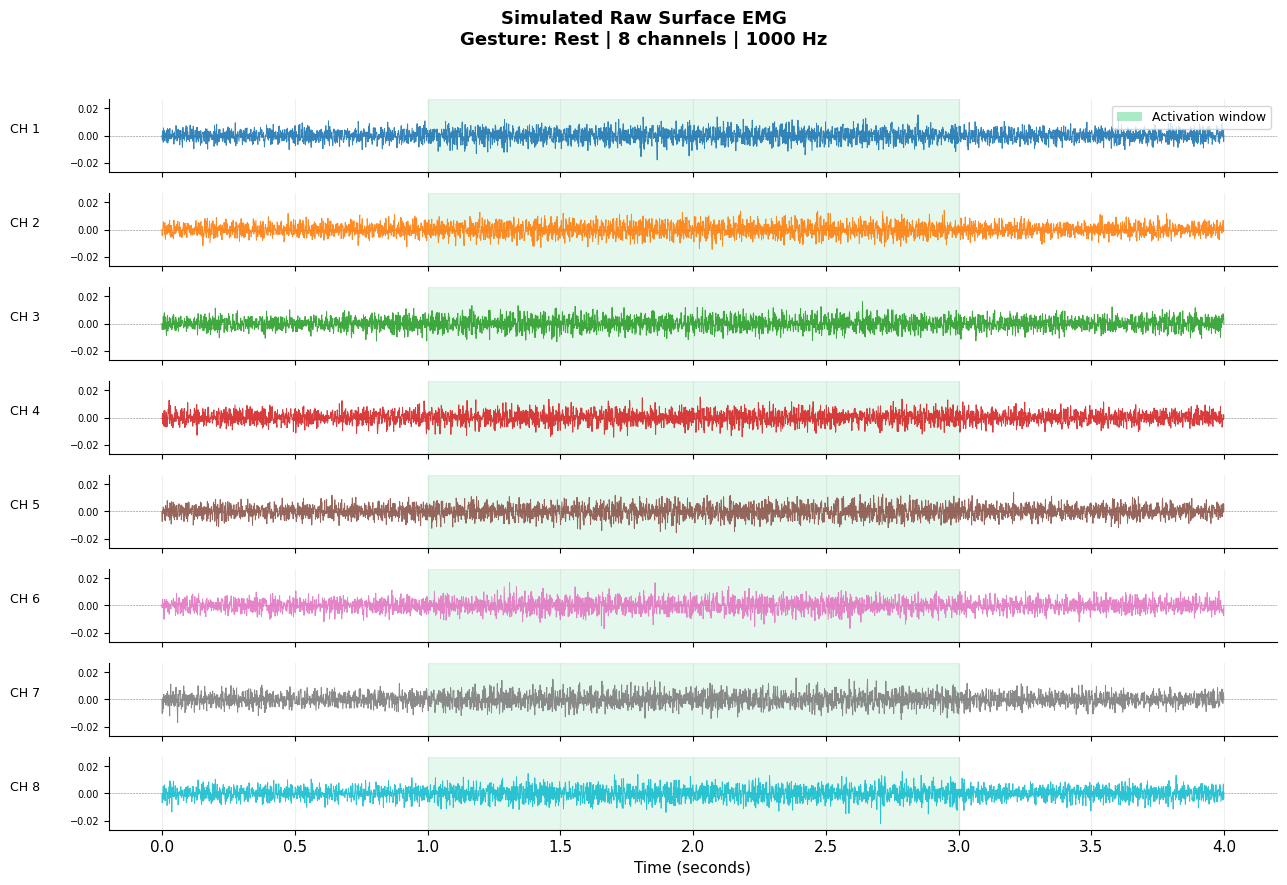

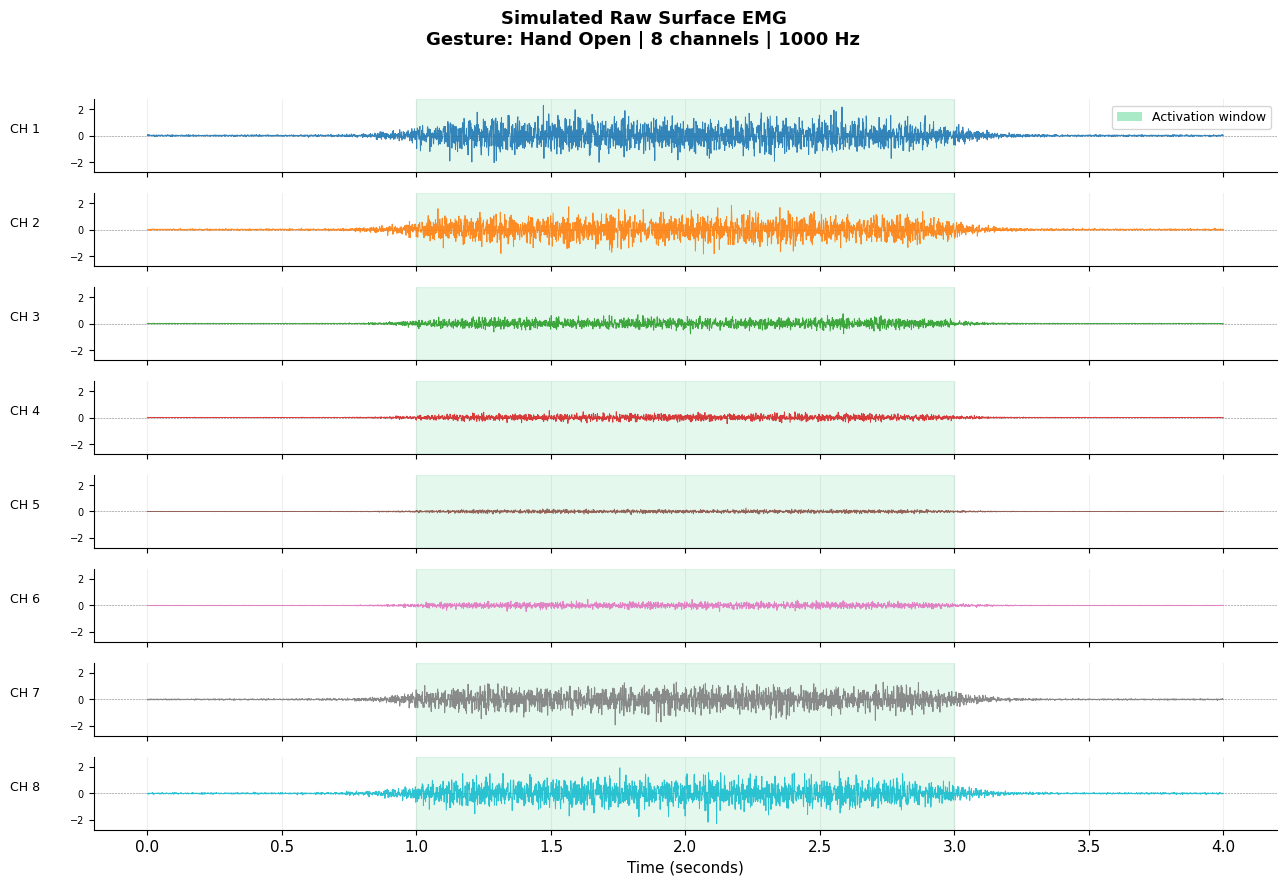

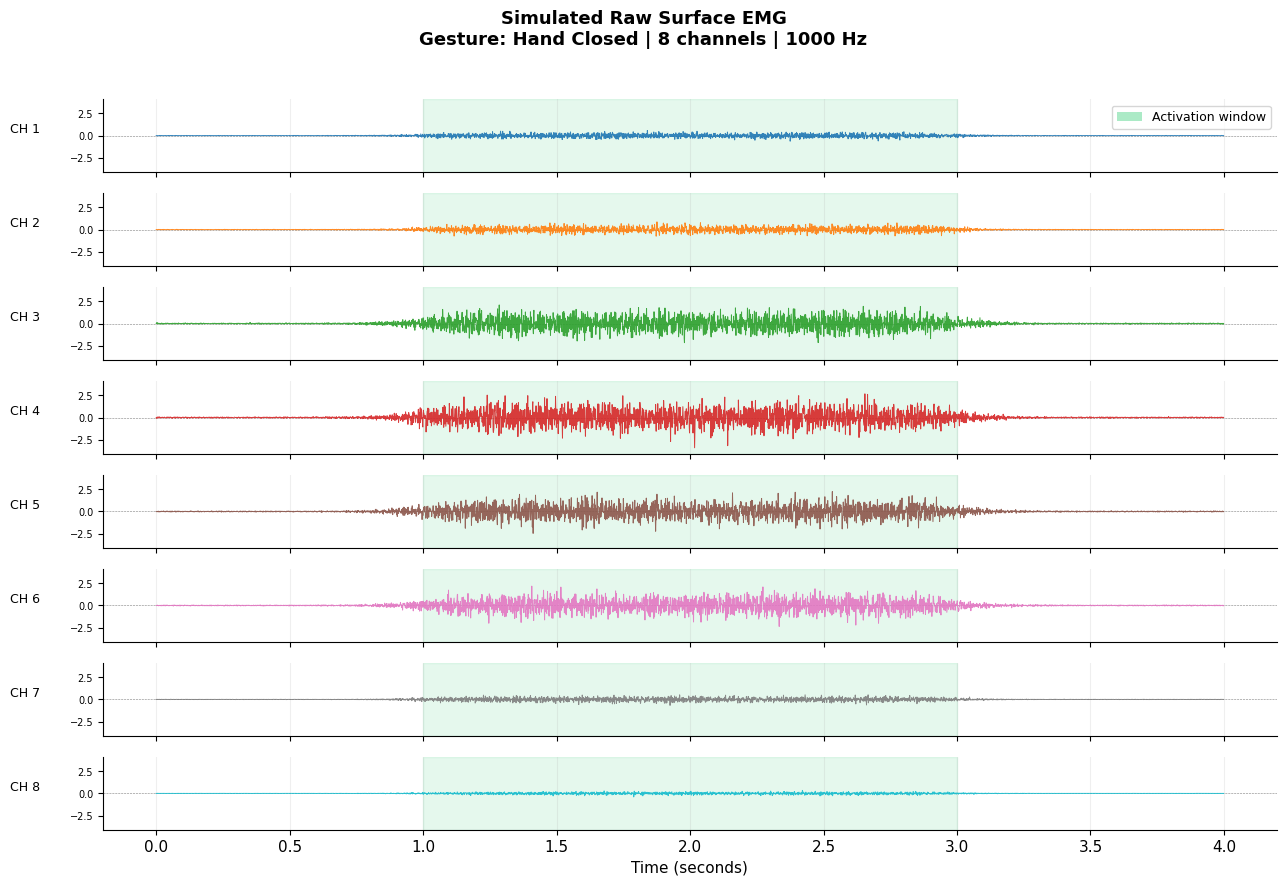

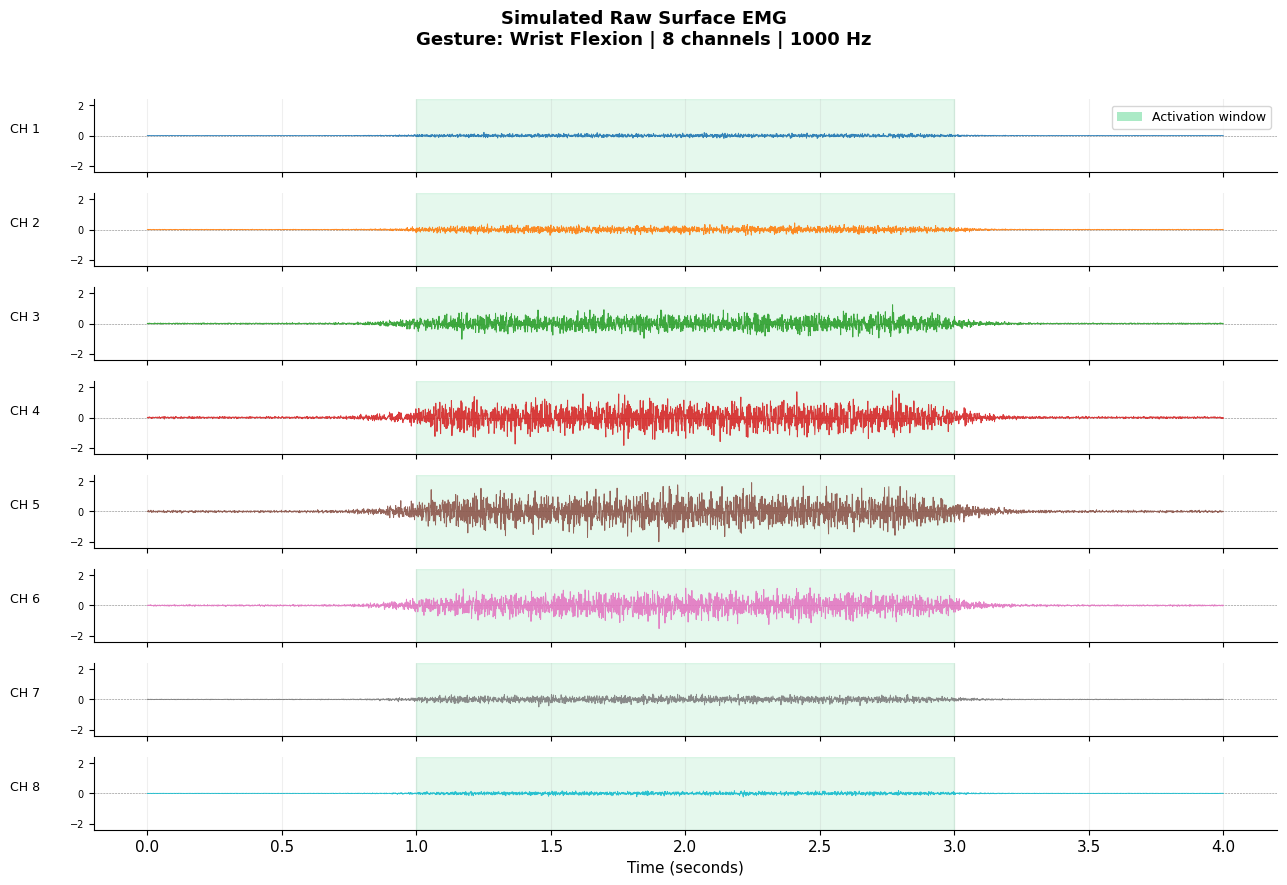

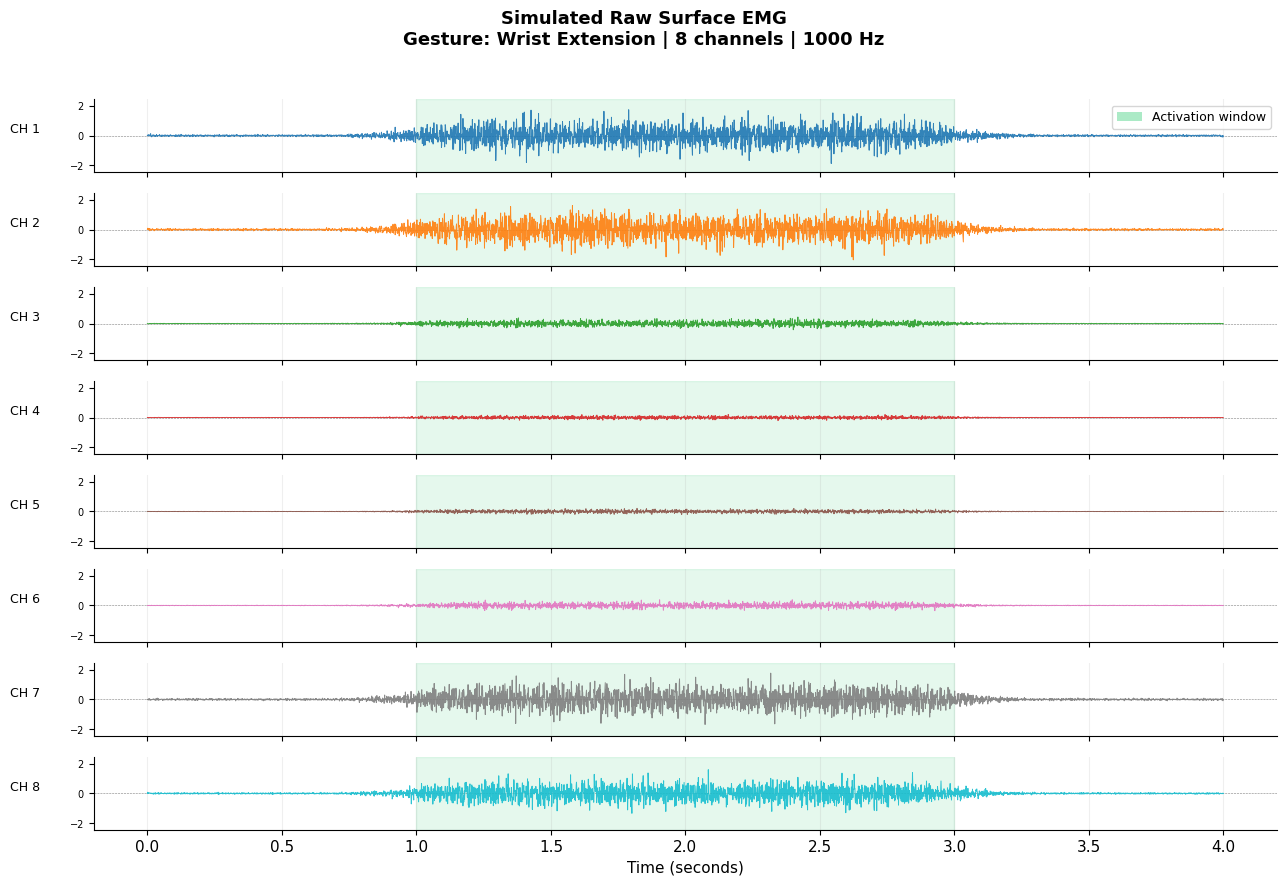

In [6]:
# =============================================================================
# SOLUTION 2.1 -- Full multi-channel EMG visualization
# Read through this carefully even if you solved the basic version above
# =============================================================================

def plot_raw_emg(emg, t, title="Raw EMG", gesture_name="", active_start=1.0, active_end=3.0):
    """
    Plot all channels of a single EMG trial in stacked subplots.
    
    Parameters
    ----------
    emg          : np.ndarray, shape (n_samples, n_channels)
    t            : np.ndarray, shape (n_samples,)  -- time axis
    title        : str -- overall figure title
    gesture_name : str -- displayed in title
    active_start : float -- shade activation region start
    active_end   : float -- shade activation region end
    """
    n_channels = emg.shape[1]
    
    # Create stacked subplots, one per channel
    # sharex=True: all plots share the same x-axis (zoom one = zoom all)
    fig, axes = plt.subplots(
        nrows=n_channels,
        ncols=1,
        figsize=(13, 9),
        sharex=True
    )
    
    # plt.cm.tab10: a colormap with 10 distinct colors
    # np.linspace(0, 0.9, n_channels): evenly spaced values from 0 to 0.9
    # This maps each channel to a different color
    colors = plt.cm.tab10(np.linspace(0, 0.9, n_channels))
    
    # Loop over each channel and create its subplot
    for ch in range(n_channels):
        ax = axes[ch]   # Select the subplot for this channel
        
        # Plot the EMG signal for this channel
        # emg[:, ch]: all rows, column 'ch' -- i.e., all time points for channel ch
        ax.plot(t, emg[:, ch], color=colors[ch], linewidth=0.7, alpha=0.9)
        
        # Add a horizontal reference line at zero
        # linestyle='--': dashed line
        # zorder=0: draw behind the signal
        ax.axhline(0, color='gray', linewidth=0.4, linestyle='--', zorder=0)
        
        # Shade the activation period with a transparent green rectangle
        # axvspan(x_start, x_end): shades a vertical span across the full y-range
        # alpha=0.12: 12% opacity (very transparent)
        ax.axvspan(active_start, active_end, alpha=0.12, color='#2ecc71')
        
        # Y-axis label with rotation=0 (horizontal text)
        # labelpad controls the spacing between label and axis
        ax.set_ylabel(f"CH {ch+1}", fontsize=9, rotation=0, labelpad=32)
        
        # Remove redundant tick marks on y-axis for cleaner look
        ax.tick_params(axis='y', labelsize=7)
        
        # Set consistent y-axis range across all channels for visual comparison
        y_max = np.max(np.abs(emg)) * 1.2  # 20% headroom above peak
        ax.set_ylim(-y_max, y_max)
        
        # Remove top and right spines (borders) for clean look
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    
    # Only bottom subplot gets the x-axis label
    axes[-1].set_xlabel("Time (seconds)", fontsize=11)
    
    # Add x-axis gridlines (vertical lines at regular intervals)
    for ax in axes:
        ax.xaxis.set_minor_locator(plt.MultipleLocator(0.5))
        ax.grid(axis='x', which='major', alpha=0.2)
    
    # Overall figure title using f-string (formatted string)
    # f"text {variable}" inserts variable values into the string
    fig.suptitle(
        f"{title}\nGesture: {gesture_name} | {n_channels} channels | {FS} Hz",
        fontsize=13,
        fontweight='bold'
    )
    
    # Add legend manually for the shaded region
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor='#2ecc71', alpha=0.4, label='Activation window')]
    axes[0].legend(handles=legend_elements, loc='upper right', fontsize=9)
    
    # tight_layout: automatically adjust spacing so labels do not overlap
    plt.tight_layout(rect=[0, 0, 1, 0.96])  # rect leaves space for suptitle
    plt.show()


# Recreate time axis
t_axis = np.linspace(0, 4.0, emg_dataset.shape[1], endpoint=False)

# Plot one trial of each gesture
# zip(list1, list2): iterates over two lists simultaneously, giving pairs
print("Plotting one trial of each gesture...")
for gesture_name in GESTURE_NAMES:
    # Find the first trial index for this gesture
    # np.where(condition): returns indices where condition is True
    # [0][0]: get the first result from the first dimension
    label = GESTURE_CONFIG[gesture_name]['label']
    trial_idx = np.where(labels_dataset == label)[0][0]
    
    plot_raw_emg(
        emg=emg_dataset[trial_idx],
        t=t_axis,
        title="Simulated Raw Surface EMG",
        gesture_name=gesture_name
    )

---
## Section 3: Frequency Analysis -- The FFT

### Why Do We Need to Think in Frequencies?

When you look at a raw EMG signal in time (the plots above), you see a messy oscillating waveform. But **not all oscillations are EMG**. Some fast oscillations are true muscle signal. Some slow oscillations are motion artifacts. Some specific frequencies are power line interference.

To understand which frequencies are present in your signal, you use the **Fourier Transform**.

### Intuition: What Is the Fourier Transform?

Imagine you hear a chord on a piano. Your ears can pick out the individual notes (frequencies) even though your eardrums are only sensing one combined sound wave. The Fourier Transform does the same thing for signals -- it decomposes a complex waveform into its individual frequency components.

The **FFT (Fast Fourier Transform)** is an efficient algorithm to compute this decomposition.

**The output of the FFT** is a spectrum: for each frequency, it tells you how much energy the signal contains at that frequency.

### EMG Frequency Content

Real surface EMG has most of its energy in the **20 to 500 Hz** range:

- **Below 20 Hz**: Motion artifacts (electrode moving against skin), breathing, heartbeat (ECG artifact)
- **20 to 500 Hz**: True muscle electrical activity (motor unit action potentials)
- **50 or 60 Hz spike**: Power line interference (50 Hz in Europe, 60 Hz in North America)
- **Above 500 Hz**: Thermal noise from electronics, aliasing

**Nyquist theorem**: If you sample at `fs = 1000 Hz`, you can correctly represent frequencies up to `fs/2 = 500 Hz`. Any signal above 500 Hz will appear distorted (aliased). This is why an analog anti-aliasing filter is applied before sampling in real hardware.

### The Math (Plain Language)

The FFT converts your signal `x[n]` (N values in time) into `X[k]` (N complex numbers in frequency).

The **power spectrum** is `|X[k]|^2`, showing the energy at each frequency.

The frequency at index `k` is: `f[k] = k * fs / N`

You only need to look at the first half of the FFT output (indices 0 to N/2), because the second half is a mirror image for real-valued signals.

In [ ]:
# =============================================================================
# SECTION 3: FFT AND FREQUENCY ANALYSIS
# =============================================================================

def compute_and_plot_spectrum(emg, fs, channel=0, title="Power Spectrum"):
    """
    Compute and plot the power spectrum of one EMG channel.
    Also plots the time-domain signal alongside it.
    
    Parameters
    ----------
    emg     : np.ndarray, shape (n_samples, n_channels)
    fs      : int   -- sampling rate in Hz
    channel : int   -- which channel to analyze (0-indexed)
    title   : str   -- plot title
    """
    n_samples  = emg.shape[0]
    sig        = emg[:, channel]  # Extract single channel: shape (n_samples,)
    
    # ------------------------------------------------------------------
    # Compute the FFT using scipy.fft
    # fft.fft(x): returns N complex numbers
    # fft.fftfreq(N, d=1/fs): computes the frequency at each FFT index
    #   d = time spacing between samples = 1/fs
    # ------------------------------------------------------------------
    fft_vals  = fft.fft(sig)           # Complex-valued FFT output
    freqs     = fft.fftfreq(n_samples, d=1.0/fs)  # Frequency at each index
    
    # Power spectrum: |X[k]|^2
    # np.abs(complex_array): computes magnitude of complex numbers
    power = np.abs(fft_vals) ** 2
    
    # We only need the first half (positive frequencies)
    # n_samples // 2: integer division -- gives us exactly half
    half_n  = n_samples // 2
    freqs   = freqs[:half_n]    # Positive frequencies only
    power   = power[:half_n]    # Corresponding power values
    
    # Normalize power to 0-1 range for easy comparison
    power_norm = power / power.max()
    
    # ------------------------------------------------------------------
    # Create a figure with two subplots side by side
    # ncols=2: two columns
    # figsize=(14, 4): wider than tall
    # ------------------------------------------------------------------
    fig, (ax_time, ax_freq) = plt.subplots(1, 2, figsize=(14, 4))
    # Note: (ax_time, ax_freq) is tuple unpacking
    # When you have 1 row and 2 cols, axes is an array of 2 elements
    # We unpack it directly into ax_time and ax_freq
    
    # -- Left plot: time domain signal --
    t_axis = np.linspace(0, n_samples/fs, n_samples, endpoint=False)
    ax_time.plot(t_axis, sig, color='steelblue', linewidth=0.6, alpha=0.9)
    ax_time.set_xlabel("Time (seconds)")
    ax_time.set_ylabel("Amplitude (mV)")
    ax_time.set_title(f"Time Domain -- Channel {channel+1}")
    ax_time.axhline(0, color='gray', linewidth=0.4, linestyle='--')
    ax_time.axvspan(1.0, 3.0, alpha=0.12, color='#2ecc71', label='Active')
    ax_time.legend(fontsize=9)
    ax_time.spines['top'].set_visible(False)
    ax_time.spines['right'].set_visible(False)
    
    # -- Right plot: frequency domain (power spectrum) --
    ax_freq.semilogy(freqs, power_norm + 1e-10, color='darkorange', linewidth=1.0)
    # semilogy: logarithmic y-axis -- makes it easier to see both large and small values
    # + 1e-10: avoids log(0) which is undefined
    
    # Shade the EMG frequency band (20-450 Hz)
    ax_freq.axvspan(20, 450, alpha=0.12, color='#2ecc71', label='EMG band (20-450 Hz)')
    
    # Mark 50 Hz power line interference frequency
    ax_freq.axvline(50, color='red', linewidth=1.0, linestyle=':', alpha=0.7, label='50 Hz (power line)')
    
    ax_freq.set_xlabel("Frequency (Hz)")
    ax_freq.set_ylabel("Normalized Power (log scale)")
    ax_freq.set_title(f"Frequency Domain -- Channel {channel+1}")
    ax_freq.set_xlim(0, fs/2)   # Show 0 to Nyquist
    ax_freq.legend(fontsize=9)
    ax_freq.spines['top'].set_visible(False)
    ax_freq.spines['right'].set_visible(False)
    
    fig.suptitle(title, fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    return freqs, power_norm


# Analyze the frequency content of a Hand Closed trial
print("Analyzing frequency content of Hand Closed trial (Channel 1)...")
freqs, power_norm = compute_and_plot_spectrum(
    emg=emg_dataset[np.where(labels_dataset == 2)[0][0]],  # First Hand Closed trial
    fs=FS,
    channel=0,
    title="EMG Frequency Analysis -- Hand Closed, Channel 1"
)

print("\nFrequency analysis notes:")
print("  - The spectrum should show energy concentrated in the 20-450 Hz band")
print("  - Below 20 Hz: motion artifacts would appear in real data")
print("  - Above 450 Hz: high-freq noise -- we will filter this out")
print("  - The dashed red line marks 50 Hz (power line frequency in Europe)")

---
## Section 4: Bandpass Filtering

### What Is Filtering?

A filter is a mathematical operation that selectively removes certain frequency components from a signal while preserving others.

Think of it like a coffee filter: it lets the liquid through but blocks the grounds. A bandpass filter lets through a specific frequency band (like 20-450 Hz for EMG) and blocks everything else.

### Types of Filters

| Filter Type | What it keeps | EMG use case |
|-------------|--------------|---------------|
| **Low-pass** | Frequencies below cutoff | RMS envelope smoothing |
| **High-pass** | Frequencies above cutoff | Remove motion artifacts (<20 Hz) |
| **Bandpass** | Frequencies within a range | Keep EMG signal (20-450 Hz) |
| **Notch (band-stop)** | Removes a narrow band | Remove 50/60 Hz power line interference |

### The Butterworth Filter

The Butterworth filter is the most common filter in EMG research because:
- It has a **maximally flat passband** -- frequencies you want to keep are not distorted
- It has a **smooth rolloff** -- it gradually blocks frequencies outside the band
- **Filter order** controls steepness: higher order = sharper cutoff, but more computation and potential instability

### Zero-Phase Filtering: `filtfilt`

A regular filter introduces **phase shift** -- it delays different frequencies by different amounts, which distorts the shape of the signal in time.

`scipy.signal.filtfilt` applies the filter **twice**: once forward in time, once backward. These phase shifts cancel out, giving you a **zero-phase** result. The signal is not shifted in time, so your activation timing is preserved. This is critical for EMG where timing matters.

### Try It Yourself -- Task 4.1

In the cell marked `# YOUR CODE HERE` below, try to:
1. Take the first channel of one EMG trial: `emg_dataset[0][:, 0]`
2. Apply a bandpass filter using `signal.butter()` and `signal.filtfilt()`
3. Plot the original and filtered signals overlaid on each other

Do not worry about getting it perfect -- the `bandpass_filter_signal` function we wrote earlier does exactly this. Try to call that function and then manually try with `butter` + `filtfilt` to understand the components.

In [ ]:
# =============================================================================
# TASK 4.1 -- YOUR CODE HERE
# Try to manually filter one EMG channel and plot raw vs filtered
# =============================================================================

# Step 1: Get one trial, one channel
trial_emg = emg_dataset[np.where(labels_dataset == 2)[0][0]]  # First Hand Closed trial
one_channel = trial_emg[:, 0]  # Channel 0, shape (4000,)
t_axis = np.linspace(0, 4.0, len(one_channel), endpoint=False)

# YOUR CODE HERE:
# 1. Compute Nyquist frequency
# 2. Normalize cutoff frequencies (divide by Nyquist)
# 3. Design Butterworth filter with signal.butter()
# 4. Apply with signal.filtfilt()
# 5. Plot both signals overlaid



In [ ]:
# =============================================================================
# SOLUTION 4.1: Manual bandpass filtering with detailed explanation
# =============================================================================

def plot_raw_vs_filtered(emg_trial, fs, channel=0,
                          lowcut=20.0, highcut=450.0, order=4,
                          zoom_start=0.8, zoom_end=1.4):
    """
    Plot raw and filtered EMG side by side:
    - Left: full signal (raw vs filtered)
    - Right: zoomed into the transition from rest to activation
    """
    n_samples = emg_trial.shape[0]
    t         = np.linspace(0, n_samples/fs, n_samples, endpoint=False)
    raw_sig   = emg_trial[:, channel]
    
    # ------------------------------------------------------------------
    # STEP 1: Compute Nyquist frequency
    # The Nyquist frequency is HALF the sampling rate.
    # It represents the highest frequency you can represent with your data.
    # At fs=1000 Hz, you can represent signals up to 500 Hz.
    # ------------------------------------------------------------------
    nyquist = fs / 2.0   # 500.0 Hz
    
    # ------------------------------------------------------------------
    # STEP 2: Normalize cutoff frequencies to [0, 1]
    # scipy.signal functions expect frequencies as fractions of Nyquist.
    # This is a quirk of scipy's API that confuses many beginners.
    # 1.0 = Nyquist frequency (500 Hz)
    # 0.0 = DC (0 Hz)
    # 0.04 = 20 Hz (because 20/500 = 0.04)
    # 0.90 = 450 Hz (because 450/500 = 0.90)
    # ------------------------------------------------------------------
    low  = lowcut  / nyquist    # 20 / 500 = 0.04
    high = highcut / nyquist    # 450 / 500 = 0.90
    
    print(f"Filter design:")
    print(f"  Nyquist:          {nyquist} Hz")
    print(f"  Lowcut:           {lowcut} Hz  -> normalized: {low:.4f}")
    print(f"  Highcut:          {highcut} Hz -> normalized: {high:.4f}")
    print(f"  Filter order:     {order}")
    
    # ------------------------------------------------------------------
    # STEP 3: Design the Butterworth filter
    # signal.butter(N, Wn, btype):
    #   N     = filter order
    #   Wn    = [low, high] cutoff frequencies (normalized)
    #   btype = 'bandpass' (keep frequencies between low and high)
    # Returns: b (numerator coefficients) and a (denominator coefficients)
    # These are the filter's mathematical description (a transfer function)
    # ------------------------------------------------------------------
    b, a = signal.butter(order, [low, high], btype='bandpass')
    
    print(f"  Filter b coefs:   {b.shape[0]} values (numerator)")
    print(f"  Filter a coefs:   {a.shape[0]} values (denominator)")
    
    # ------------------------------------------------------------------
    # STEP 4: Apply the filter with filtfilt (zero-phase)
    # signal.filtfilt(b, a, x):
    #   Applies the filter forward, then backward
    #   Result: zero phase delay, effectively doubles the filter order
    #   axis=0: filter along the first axis (time axis)
    #           important when filtering multi-channel arrays
    # ------------------------------------------------------------------
    filtered_sig = signal.filtfilt(b, a, raw_sig)  # shape: (n_samples,)
    
    print(f"  Input signal:     min={raw_sig.min():.4f}, max={raw_sig.max():.4f}")
    print(f"  Filtered signal:  min={filtered_sig.min():.4f}, max={filtered_sig.max():.4f}")
    
    # ------------------------------------------------------------------
    # STEP 5: Visualize
    # ------------------------------------------------------------------
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
    
    # Full signal view
    ax1.plot(t, raw_sig,      color='steelblue',  linewidth=0.6, alpha=0.6, label='Raw')
    ax1.plot(t, filtered_sig, color='darkorange', linewidth=0.8, alpha=0.9, label='Filtered')
    ax1.axvspan(1.0, 3.0, alpha=0.10, color='#2ecc71')
    ax1.set_xlabel("Time (seconds)")
    ax1.set_ylabel("Amplitude (mV)")
    ax1.set_title(f"Full Signal -- Channel {channel+1}")
    ax1.legend(fontsize=9)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    
    # Zoomed view: transition from rest to activation
    # Boolean indexing: (t >= zoom_start) & (t <= zoom_end)
    # Creates a boolean array; True where condition holds
    # Use it to select only those time points
    zoom_mask = (t >= zoom_start) & (t <= zoom_end)
    ax2.plot(t[zoom_mask], raw_sig[zoom_mask],      color='steelblue',  linewidth=0.8, alpha=0.7, label='Raw')
    ax2.plot(t[zoom_mask], filtered_sig[zoom_mask], color='darkorange', linewidth=1.2, alpha=0.95, label='Filtered')
    ax2.axvline(1.0, color='green', linewidth=1.5, linestyle='--', alpha=0.7, label='Activation start')
    ax2.set_xlabel("Time (seconds)")
    ax2.set_ylabel("Amplitude (mV)")
    ax2.set_title(f"Zoomed View: Rest-to-Activation Transition")
    ax2.legend(fontsize=9)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    
    fig.suptitle("Raw vs Bandpass Filtered EMG (20-450 Hz, 4th order Butterworth)",
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    return filtered_sig


# Run the comparison
trial_hc = emg_dataset[np.where(labels_dataset == 2)[0][0]]
filtered_ch0 = plot_raw_vs_filtered(trial_hc, fs=FS, channel=0)

In [ ]:
# =============================================================================
# SECTION 4B: Filter the entire dataset
# Apply bandpass filtering to all trials and all channels at once
# =============================================================================
#
# SYNTAX LESSON: np.zeros_like(array)
# Creates a new array with the same shape and dtype as 'array', filled with zeros.
# This is the standard way to pre-allocate output arrays before filling them in a loop.
# It is more efficient than building a list and stacking at the end for large arrays.

print("Applying bandpass filter to all trials...")
print(f"  Input shape: {emg_dataset.shape}  -- (trials, samples, channels)")

# Pre-allocate output array with same shape as input
emg_filtered = np.zeros_like(emg_dataset)  # shape: (50, 4000, 8)

# Filter each trial independently
# We use enumerate() to get both index (i) and value (trial_emg) simultaneously
for i, trial_emg in enumerate(emg_dataset):
    # trial_emg shape: (4000, 8)
    # bandpass_filter_signal handles multi-channel arrays (axis=0)
    emg_filtered[i] = bandpass_filter_signal(trial_emg, FS, lowcut=20.0, highcut=450.0)
    
    # Print progress every 10 trials
    # i % 10 == 9: True when i is 9, 19, 29, 39, 49
    if (i + 1) % 10 == 0:
        print(f"  Filtered trial {i+1}/{len(emg_dataset)}")

print(f"\nFiltering complete!")
print(f"  Output shape: {emg_filtered.shape}")
print(f"  Raw amplitude:      {emg_dataset.std():.5f} mV (std)")
print(f"  Filtered amplitude: {emg_filtered.std():.5f} mV (std)")
print("  (std = standard deviation: measure of signal spread)")

---
## Section 5: Rectification and the RMS Envelope

### Why Rectify?

Raw EMG oscillates symmetrically above and below zero. If you average it over any window, the positive and negative values cancel out and you get approximately zero -- even during a strong contraction. That tells you nothing about muscle activation.

**Rectification** means taking the absolute value of every sample: `|x|`. Now all values are positive. The signal rises when the muscle is active and falls during rest. This represents the **magnitude of muscle electrical activity**.

### The RMS Envelope

**Root Mean Square (RMS)** is a better way to represent the signal magnitude because it accounts for the signal's energy:

```
RMS = sqrt( mean( x^2 ) )
```

In practice, for a continuous signal we compute a **moving RMS**: for each time point, we compute the RMS over a short window of surrounding samples. This produces a smooth envelope that follows the signal's amplitude.

Think of the RMS envelope as the "energy trace" of the muscle -- it tells you how active the muscle was at each moment in time.

### Research Note

The RMS envelope is used in EMG research for:
- Visualizing muscle activation timing
- Segmenting active vs. rest periods
- As a feature itself (RMS is one of the most commonly used EMG features)
- Normalization: dividing by maximum voluntary contraction (MVC) RMS

### Normalization

Different people, different days, different electrode positions all produce different raw EMG amplitudes. **Normalization** puts signals on a common scale so that a classifier trained on one session can potentially be applied to another.

Common approaches:
- Divide by the channel's maximum value in the training data
- Divide by the channel's standard deviation (z-score normalization)
- Divide by the MVC (maximum voluntary contraction) value -- the standard in clinical EMG

In [ ]:
# =============================================================================
# SECTION 5A: RECTIFICATION
# =============================================================================
#
# SYNTAX LESSON: np.abs()
# np.abs(x) computes the absolute value of every element in array x.
# Works on any shape. Element-wise operation (fast, vectorized).
# This is MUCH faster than a Python for-loop over individual elements.

def rectify(emg):
    """
    Full-wave rectification: take the absolute value of all samples.
    
    Parameters
    ----------
    emg : np.ndarray -- any shape
    
    Returns
    -------
    np.ndarray -- absolute values, same shape as input
    """
    return np.abs(emg)


# Quick test
test_sig = np.array([-1.5, 0.3, -0.8, 1.2, -0.1])
print("Rectification test:")
print(f"  Input:  {test_sig}")
print(f"  Output: {rectify(test_sig)}")
print("  (All negative values become positive)")

# Apply to the whole dataset
emg_rectified = rectify(emg_filtered)   # shape: (50, 4000, 8)
print(f"\nRectification applied to full dataset.")
print(f"  Input min:  {emg_filtered.min():.4f} mV")
print(f"  Output min: {emg_rectified.min():.4f} mV  (no more negative values)")

In [ ]:
# =============================================================================
# SECTION 5B: MOVING RMS ENVELOPE
# =============================================================================

def moving_rms(emg, window_samples):
    """
    Compute a moving (sliding) RMS envelope.
    
    For each time point t, computes RMS over the window centered at t.
    
    RMS formula: sqrt( mean( x[t-w//2 : t+w//2]^2 ) )
    
    Parameters
    ----------
    emg            : np.ndarray, shape (n_samples,) or (n_samples, n_channels)
    window_samples : int -- number of samples in the RMS window
                          At 1000 Hz, window=50 means a 50ms window
    
    Returns
    -------
    rms_env : np.ndarray -- RMS envelope, same shape as input
    """
    is_1d = emg.ndim == 1  # Check if input is 1D or 2D
    if is_1d:
        emg = emg[:, np.newaxis]  # Make it 2D: (n_samples, 1)
    
    n_samples, n_channels = emg.shape
    rms_env = np.zeros_like(emg, dtype=float)
    half_w  = window_samples // 2  # Half-window size for centering
    
    # Compute squared signal once (reused for each window position)
    emg_sq = emg ** 2  # Element-wise squaring: x^2 for every sample
    
    # Sliding window: for each time index t, compute RMS over [t-half_w, t+half_w]
    for t in range(n_samples):
        # np.clip(value, min, max): clip a value to stay within [min, max]
        # This handles edges where the window would go out of bounds
        start = np.clip(t - half_w, 0, n_samples - 1)  # Don't go below 0
        end   = np.clip(t + half_w, 0, n_samples - 1)  # Don't exceed array end
        
        # mean(x^2) along axis=0 (average over time within the window)
        # sqrt of the mean gives RMS
        rms_env[t, :] = np.sqrt(np.mean(emg_sq[start:end, :], axis=0))
    
    # Return 1D if input was 1D
    if is_1d:
        return rms_env[:, 0]
    return rms_env


# Compute RMS envelope for one trial to visualize the pipeline stages
trial_idx = np.where(labels_dataset == 2)[0][0]  # First Hand Closed trial
trial_raw  = emg_dataset[trial_idx]              # Raw
trial_filt = emg_filtered[trial_idx]             # Filtered
trial_rect = emg_rectified[trial_idx]            # Rectified

# RMS window: 50ms at 1000 Hz = 50 samples
RMS_WINDOW_MS = 50
rms_window_samples = int(RMS_WINDOW_MS * FS / 1000)  # Convert ms to samples
print(f"RMS window: {RMS_WINDOW_MS} ms = {rms_window_samples} samples")

trial_rms = moving_rms(trial_filt, rms_window_samples)  # shape: (4000, 8)
print(f"RMS envelope computed. Shape: {trial_rms.shape}")

In [ ]:
# =============================================================================
# SECTION 5C: VISUALIZE THE FULL PROCESSING PIPELINE
# Raw -> Filtered -> Rectified -> RMS Envelope
# =============================================================================

def plot_processing_pipeline(trial_raw, trial_filt, trial_rect, trial_rms,
                              fs, channel=0, active_start=1.0, active_end=3.0):
    """
    4-row plot showing each processing stage for one channel.
    """
    n_samples = trial_raw.shape[0]
    t = np.linspace(0, n_samples/fs, n_samples, endpoint=False)
    
    # 4 rows, 1 column
    fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
    
    # Signal at each stage for the selected channel
    stages = [
        (trial_raw[:,  channel], 'steelblue',   'Raw EMG',         '(mV)'),
        (trial_filt[:, channel], 'darkorange',  'Bandpass Filtered\n(20-450 Hz)', '(mV)'),
        (trial_rect[:, channel], 'mediumseagreen','Rectified',     '(|mV|)'),
        (trial_rms[:,  channel], 'crimson',      'RMS Envelope\n(50ms window)',   '(mV RMS)'),
    ]
    
    for ax, (sig, color, stage_name, ylabel) in zip(axes, stages):
        ax.plot(t, sig, color=color, linewidth=0.7, alpha=0.9)
        ax.axvspan(active_start, active_end, alpha=0.10, color='#2ecc71')
        ax.axhline(0, color='gray', linewidth=0.4, linestyle='--', alpha=0.5)
        ax.set_ylabel(f"{stage_name}\n{ylabel}", fontsize=9)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.tick_params(labelsize=8)
    
    axes[-1].set_xlabel("Time (seconds)", fontsize=11)
    
    fig.suptitle(
        f"EMG Processing Pipeline -- Channel {channel+1}\n"
        f"Green shading = activation window (1.0s to 3.0s)",
        fontsize=13, fontweight='bold'
    )
    plt.tight_layout()
    plt.show()


plot_processing_pipeline(trial_raw, trial_filt, trial_rect, trial_rms, FS, channel=0)
print("\nWhat you should observe:")
print("  Row 1 (Raw):       Noisy signal oscillating around zero. Hard to interpret.")
print("  Row 2 (Filtered):  Cleaner oscillations. Low-freq drift and high-freq noise removed.")
print("  Row 3 (Rectified): All positive. Amplitude envelope now visible.")
print("  Row 4 (RMS):       Smooth envelope. Clearly shows rest vs. activation.")

In [ ]:
# =============================================================================
# SECTION 5D: NORMALIZATION
# =============================================================================
#
# RESEARCH NOTE:
# EMG amplitude varies enormously between:
#   - Different people (muscle size, fat layer thickness, fitness)
#   - Different sessions (electrode placement, sweat, fatigue)
#   - Different channels (some muscles are stronger or closer to the surface)
#
# Without normalization, a classifier trained on Session 1 might fail on Session 2
# simply because the raw amplitudes differ, even if the gesture patterns are the same.
# This is one source of the "inter-session variability" problem in EMG research.

def normalize_emg(emg_dataset, method='zscore'):
    """
    Normalize EMG channels across the entire dataset.
    
    Parameters
    ----------
    emg_dataset : np.ndarray, shape (n_trials, n_samples, n_channels)
    method      : str
        'zscore'  -- subtract mean, divide by std (zero mean, unit variance)
        'maxabs'  -- divide by max absolute value per channel (range: -1 to 1)
    
    Returns
    -------
    emg_norm : np.ndarray -- normalized, same shape as input
    params   : dict       -- normalization parameters (for applying to new data)
    """
    n_trials, n_samples, n_channels = emg_dataset.shape
    emg_norm = np.zeros_like(emg_dataset, dtype=float)
    params   = {}
    
    if method == 'zscore':
        for ch in range(n_channels):
            # Get all samples across all trials for this channel
            # emg_dataset[:, :, ch] shape: (n_trials, n_samples)
            # .ravel() flattens to 1D: (n_trials * n_samples,)
            all_samples = emg_dataset[:, :, ch].ravel()
            
            ch_mean = np.mean(all_samples)
            ch_std  = np.std(all_samples)
            
            # Z-score: (x - mean) / std
            # Each channel gets its own mean and std
            emg_norm[:, :, ch] = (emg_dataset[:, :, ch] - ch_mean) / (ch_std + 1e-10)
            # + 1e-10: tiny value to prevent division by zero if std=0
            
            params[f'ch{ch}_mean'] = ch_mean
            params[f'ch{ch}_std']  = ch_std
    
    elif method == 'maxabs':
        for ch in range(n_channels):
            all_samples  = emg_dataset[:, :, ch].ravel()
            ch_max       = np.max(np.abs(all_samples))
            emg_norm[:, :, ch] = emg_dataset[:, :, ch] / (ch_max + 1e-10)
            params[f'ch{ch}_max'] = ch_max
    
    return emg_norm, params


# Apply z-score normalization to the filtered dataset
emg_normalized, norm_params = normalize_emg(emg_filtered, method='zscore')

print("Z-score normalization applied.")
print(f"  Before: mean={emg_filtered.mean():.4f}, std={emg_filtered.std():.4f}")
print(f"  After:  mean={emg_normalized.mean():.4f}, std={emg_normalized.std():.4f}")
print(f"  (After normalization: mean ≈ 0, std ≈ 1)")
print(f"\nNormalization parameters stored (needed to apply to new/test data):")
for k in list(norm_params.keys())[:4]:
    print(f"  {k}: {norm_params[k]:.6f}")
print(f"  ... and {len(norm_params)-4} more parameters")

---
## Section 6: Windowing -- Splitting the Signal into Chunks

### Why Do We Use Windows?

Machine learning classifiers need **fixed-size numerical inputs**. A raw EMG trial is thousands of samples long, and its length can vary. You cannot feed a 4000-sample time-series directly into a classifier like LDA or SVM.

Instead, we split the signal into short **windows** (also called segments or epochs). Each window is a short slice of the signal, typically 100 to 300 milliseconds long. From each window, we extract a fixed set of numerical features. The features from one window become one row in the feature matrix.

### Window Size and Step Size

**Window size (W)**: how many samples are in each window. At 1000 Hz:
- 100ms window = 100 samples
- 200ms window = 200 samples
- 250ms window = 250 samples

**Step size (S)** (also called stride or increment): how far the window moves forward for each new window.
- If step = window size: **non-overlapping windows** (no redundancy, fewer windows)
- If step < window size: **overlapping windows** (more windows, more temporal resolution, data augmentation)

**Overlap percentage**: `(1 - step/window) * 100%`
- Step = 50, window = 200: `(1 - 50/200)*100 = 75%` overlap

### Why 150-250ms Windows?

This is a critical practical constraint: the **controller delay** in a prosthetic hand must be short enough for natural control. Research has shown that approximately **200-300ms total delay** is the maximum humans can tolerate before it feels unnatural. The window size contributes to this delay (you must wait for the window to fill before classifying).

Typical research choices:
- Window: 200ms (200 samples at 1000 Hz)
- Step: 50ms (50 samples at 1000 Hz) -- 75% overlap
- This gives 20 classification outputs per second (50ms between outputs)

### The Number of Windows

For a signal with `N` samples, window size `W`, and step size `S`:

```
n_windows = floor( (N - W) / S ) + 1
```

Example: N=4000, W=200, S=50: `floor((4000-200)/50) + 1 = 77 windows`

### Try It Yourself -- Task 6.1

Before looking at the solution, write a function that takes a 1D signal and splits it into overlapping windows. Each window should be a row in the output.

Hint: Use a loop. For each window index `i`, the window starts at `i * step_size` and ends at `i * step_size + window_size`.

In [ ]:
# =============================================================================
# TASK 6.1 -- YOUR CODE HERE
# Write a function to split a 1D signal into overlapping windows
# =============================================================================

def split_into_windows_basic(signal_1d, window_size, step_size):
    """
    Split a 1D signal into overlapping windows.
    
    Parameters
    ----------
    signal_1d   : np.ndarray, shape (n_samples,)
    window_size : int  -- number of samples per window
    step_size   : int  -- number of samples to advance between windows
    
    Returns
    -------
    windows : np.ndarray, shape (n_windows, window_size)
    """
    # YOUR CODE HERE
    # 1. Calculate how many windows fit
    # 2. Create an empty list or pre-allocated array
    # 3. Loop to extract each window
    # 4. Stack and return
    
    pass  # Remove this and fill in your code


# Test with a simple 1D signal
test_sig = np.arange(20)  # [0, 1, 2, ..., 19]
# windows = split_into_windows_basic(test_sig, window_size=6, step_size=2)
# print("Your windows:")
# print(windows)
# Expected output: first window [0,1,2,3,4,5], second [2,3,4,5,6,7], etc.

In [ ]:
# =============================================================================
# SOLUTION 6.1 + FULL MULTI-CHANNEL WINDOWING FUNCTION
# =============================================================================

def extract_windows(emg_trial, window_size, step_size):
    """
    Split a multi-channel EMG trial into overlapping windows.
    
    Parameters
    ----------
    emg_trial   : np.ndarray, shape (n_samples, n_channels)
    window_size : int  -- samples per window (e.g., 200 samples = 200ms at 1000Hz)
    step_size   : int  -- samples to advance (e.g., 50 samples = 50ms at 1000Hz)
    
    Returns
    -------
    windows : np.ndarray, shape (n_windows, window_size, n_channels)
    """
    n_samples, n_channels = emg_trial.shape
    
    # ------------------------------------------------------------------
    # Calculate total number of windows that fit in the signal
    # Formula: floor((n_samples - window_size) / step_size) + 1
    # // is Python integer division (same as floor division for positive numbers)
    # ------------------------------------------------------------------
    n_windows = (n_samples - window_size) // step_size + 1
    
    # Pre-allocate output array
    # Shape: (n_windows, window_size, n_channels)
    windows = np.zeros((n_windows, window_size, n_channels), dtype=emg_trial.dtype)
    
    # Fill in each window
    for w_idx in range(n_windows):
        # Start sample of this window
        start = w_idx * step_size
        
        # End sample (exclusive, Python slicing convention)
        end   = start + window_size
        
        # Extract the window for all channels simultaneously
        # emg_trial[start:end, :] -- rows from start to end, all columns
        windows[w_idx, :, :] = emg_trial[start:end, :]
    
    return windows


# ------------------------------------------------------------------
# Demonstrate with a simple test case first
# ------------------------------------------------------------------
print("=== WINDOWING DEMONSTRATION ===")

# Simple 1D example with visible numbers
test_1d = np.arange(20)[:, np.newaxis]  # shape (20, 1): values 0 to 19
test_windows = extract_windows(test_1d, window_size=6, step_size=2)
print(f"\n1D test: signal [0..19], window=6, step=2")
print(f"  n_windows formula: ({len(test_1d)} - 6) // 2 + 1 = {(len(test_1d)-6)//2+1}")
print(f"  Resulting shape: {test_windows.shape}  -- (windows, window_size, channels)")
print(f"  First 3 windows (channel 0):")
for i in range(3):
    print(f"    Window {i}: {test_windows[i, :, 0]}  (starts at sample {i*2})")

# ------------------------------------------------------------------
# Real EMG windowing
# ------------------------------------------------------------------
WINDOW_MS   = 200   # 200 milliseconds
STEP_MS     = 50    # 50 milliseconds (75% overlap)

# Convert ms to samples
WINDOW_SAMPLES = int(WINDOW_MS * FS / 1000)   # 200ms * 1000Hz/1000 = 200 samples
STEP_SAMPLES   = int(STEP_MS   * FS / 1000)   # 50ms  * 1000Hz/1000 = 50 samples
OVERLAP_PCT    = (1 - STEP_SAMPLES / WINDOW_SAMPLES) * 100

print(f"\n=== EMG WINDOWING PARAMETERS ===")
print(f"  Window size: {WINDOW_MS} ms = {WINDOW_SAMPLES} samples")
print(f"  Step size:   {STEP_MS} ms = {STEP_SAMPLES} samples")
print(f"  Overlap:     {OVERLAP_PCT:.0f}%")

# Test on one trial
trial_example = emg_normalized[0]  # shape: (4000, 8)
windows_example = extract_windows(trial_example, WINDOW_SAMPLES, STEP_SAMPLES)
print(f"\nOne trial windowed:")
print(f"  Input shape:  {trial_example.shape}  -- (samples, channels)")
print(f"  Output shape: {windows_example.shape}  -- (windows, window_size, channels)")
print(f"  n_windows formula: ({trial_example.shape[0]} - {WINDOW_SAMPLES}) // {STEP_SAMPLES} + 1 = {windows_example.shape[0]}")

In [ ]:
# =============================================================================
# SECTION 6B: VISUALIZE WINDOWS ON THE SIGNAL
# Show how windows slide over the signal with overlap
# =============================================================================

def visualize_windowing(emg_trial, fs, window_samples, step_samples,
                         channel=0, n_windows_to_show=6):
    """
    Visualize the first few windows overlaid on the EMG signal.
    """
    n_samples  = emg_trial.shape[0]
    t          = np.linspace(0, n_samples/fs, n_samples, endpoint=False)
    sig        = emg_trial[:, channel]
    
    fig, ax = plt.subplots(figsize=(14, 4))
    
    # Plot the full signal
    ax.plot(t, sig, color='lightblue', linewidth=0.7, alpha=0.9, zorder=1, label='EMG signal')
    
    # Generate colors for each window shown
    window_colors = plt.cm.plasma(np.linspace(0.1, 0.9, n_windows_to_show))
    
    # Draw each window as a shaded rectangle
    for w in range(n_windows_to_show):
        start_sample = w * step_samples
        end_sample   = start_sample + window_samples
        start_time   = start_sample / fs
        end_time     = end_sample   / fs
        
        # axvspan draws a vertical colored band
        ax.axvspan(start_time, end_time,
                   alpha=0.25,
                   color=window_colors[w],
                   label=f'Window {w+1}' if w < 4 else None,
                   zorder=2)
        
        # Mark the start of each window with a vertical line
        ax.axvline(start_time, color=window_colors[w], linewidth=1.5,
                   alpha=0.7, linestyle='-', zorder=3)
        
        # Label the window number above the signal
        mid_time = (start_time + end_time) / 2
        ax.text(mid_time, sig.max() * 1.05, f'W{w+1}',
                ha='center', va='bottom', fontsize=8,
                color=window_colors[w], fontweight='bold')
    
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.set_title(
        f"Sliding Windows on EMG Signal -- Channel {channel+1}\n"
        f"Window: {window_samples/fs*1000:.0f}ms, "
        f"Step: {step_samples/fs*1000:.0f}ms, "
        f"Overlap: {(1-step_samples/window_samples)*100:.0f}%",
        fontsize=12
    )
    # Set x-limit to show only the windowed region clearly
    ax.set_xlim(-0.02, (n_windows_to_show * step_samples + window_samples) / fs + 0.05)
    ax.legend(fontsize=8, loc='upper right', ncol=2)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    plt.tight_layout()
    plt.show()


visualize_windowing(
    emg_trial=emg_normalized[0],
    fs=FS,
    window_samples=WINDOW_SAMPLES,
    step_samples=STEP_SAMPLES,
    channel=0,
    n_windows_to_show=7
)

print("Notice how consecutive windows OVERLAP.")
print(f"With 75% overlap, window 2 starts at {STEP_MS}ms but window 1 ends at {WINDOW_MS}ms.")
print(f"The first {WINDOW_SAMPLES - STEP_SAMPLES} samples of window 2 were already in window 1.")

---
## Section 7: Feature Extraction

### From Waveforms to Numbers: Why Features?

Each window contains `window_size x n_channels` raw numbers. For a 200ms window with 8 channels at 1000 Hz, that is 200 x 8 = 1600 raw numbers. That is too many, too redundant, and not very meaningful for a classifier.

**Features** are compact, meaningful numerical summaries of each window. Instead of 1600 raw numbers, you compute 5 features per channel, giving you 5 x 8 = 40 numbers. These 40 numbers capture the essential information about the muscle activity pattern in that window.

### The Five Classic EMG Features

These features come from Hudgins et al. (1993), one of the most cited papers in myoelectric control. They remain widely used today because they are simple, fast, and effective.

Let `x` be the samples in one window, `N` = number of samples:

---

**1. Mean Absolute Value (MAV)**

```
MAV = (1/N) * sum( |x[n]| )
```
The average absolute amplitude. Higher during muscle contraction, lower at rest. Measures how energetic the muscle is. This is the simplest and one of the most powerful EMG features.

---

**2. Variance (VAR)**

```
VAR = (1/(N-1)) * sum( x[n]^2 )
```
Note: Since EMG is approximately zero-mean, variance ≈ power. Measures signal power. Closely related to RMS.

---

**3. Waveform Length (WL)**

```
WL = sum( |x[n+1] - x[n]| )
```
The cumulative length of the waveform (sum of absolute first differences). Measures the complexity and speed of oscillations. High WL means the signal is changing rapidly (many fast motor unit firings).

---

**4. Zero Crossings (ZC)**

```
ZC = count of times where x[n] * x[n+1] < 0 AND |x[n+1] - x[n]| > threshold
```
How many times the signal crosses zero. Related to the frequency content of the signal -- higher frequency means more zero crossings. The threshold filters out noise-induced crossings.

---

**5. Slope Sign Changes (SSC)**

```
SSC = count of times where (x[n]-x[n-1]) * (x[n+1]-x[n]) < 0 AND magnitude condition
```
How many times the slope of the signal changes direction (from rising to falling or vice versa). Also related to signal frequency. Complementary to ZC.

---

### The Feature Vector

For 8 channels and 5 features:
```
[MAV_ch1, MAV_ch2, ..., MAV_ch8,
 VAR_ch1, VAR_ch2, ..., VAR_ch8,
 WL_ch1,  WL_ch2,  ..., WL_ch8,
 ZC_ch1,  ZC_ch2,  ..., ZC_ch8,
 SSC_ch1, SSC_ch2, ..., SSC_ch8]
```
= 40 numbers per window. This is one row in the feature matrix.

**Reference**: Hudgins, B., Parker, P., & Scott, R. N. (1993). A new strategy for multifunction myoelectric control. *IEEE Transactions on Biomedical Engineering*, 40(1), 82-94.

In [ ]:
# =============================================================================
# SECTION 7A: INDIVIDUAL FEATURE FUNCTIONS
# Each function takes a 2D window (window_size x n_channels) and returns
# a 1D array of feature values (one per channel)
# =============================================================================

def feature_mav(window):
    """
    Mean Absolute Value (MAV).
    Average rectified amplitude of the signal in the window.
    
    Formula: MAV = mean(|x|) = (1/N) * sum(|x[n]|)
    
    Parameters
    ----------
    window : np.ndarray, shape (window_size, n_channels)
    
    Returns
    -------
    np.ndarray, shape (n_channels,)  -- one MAV value per channel
    """
    # np.abs(window): absolute value of every element
    # .mean(axis=0): average over the time axis (rows)
    #   axis=0 collapses the first dimension, leaving (n_channels,)
    return np.abs(window).mean(axis=0)


def feature_var(window):
    """
    Variance (VAR) = signal power (for zero-mean EMG).
    
    Formula: VAR = (1/(N-1)) * sum(x[n]^2)
    Note: We use (N-1) denominator (Bessel's correction) -- standard in statistics
    """
    N = window.shape[0]  # number of samples in the window
    
    # window ** 2: element-wise squaring (x^2 for every element)
    # .sum(axis=0): sum over time axis
    # / (N - 1): unbiased variance denominator
    return (window ** 2).sum(axis=0) / (N - 1)


def feature_wl(window):
    """
    Waveform Length (WL) = cumulative arc length of the waveform.
    
    Formula: WL = sum(|x[n+1] - x[n]|) for n = 0 to N-2
    """
    # np.diff(window, axis=0): computes x[n+1] - x[n] for consecutive samples
    #   Input shape:  (window_size, n_channels)
    #   Output shape: (window_size-1, n_channels)  -- one fewer row
    diffs = np.diff(window, axis=0)
    
    # np.abs(diffs).sum(axis=0): sum of absolute differences over time
    return np.abs(diffs).sum(axis=0)


def feature_zc(window, threshold=0.01):
    """
    Zero Crossings (ZC).
    Count how many times the signal crosses zero, with noise threshold.
    
    A crossing is counted only if |x[n+1] - x[n]| > threshold,
    which prevents noise-induced false crossings near zero.
    
    Parameters
    ----------
    window    : np.ndarray, shape (window_size, n_channels)
    threshold : float -- minimum amplitude change to count as a crossing
    """
    # Check if consecutive samples have OPPOSITE signs:
    #   window[:-1, :] = all rows except the last
    #   window[1:,  :] = all rows except the first
    #   Multiplying them: negative if signs differ (one positive, one negative)
    sign_change = window[:-1, :] * window[1:, :] < 0   # (window_size-1, n_channels), boolean
    
    # Also require the magnitude change to exceed threshold
    amplitude_condition = np.abs(np.diff(window, axis=0)) >= threshold  # same shape, boolean
    
    # Both conditions must be true: use & (bitwise AND for boolean arrays)
    # .sum(axis=0): count True values along the time axis
    return (sign_change & amplitude_condition).sum(axis=0).astype(float)


def feature_ssc(window, threshold=0.01):
    """
    Slope Sign Changes (SSC).
    Count how many times the slope direction changes (local maxima/minima).
    
    A slope sign change at point n means:
    (x[n]-x[n-1]) and (x[n+1]-x[n]) have opposite signs
    """
    # First differences: slope between each pair of consecutive samples
    # Shape: (window_size-1, n_channels)
    diffs = np.diff(window, axis=0)
    
    # Compare consecutive slopes:
    #   diffs[:-1, :] = slope from n-1 to n
    #   diffs[1:,  :] = slope from n to n+1
    # Negative product means opposite signs (slope changed direction)
    slope_change = diffs[:-1, :] * diffs[1:, :] < 0   # (window_size-2, n_channels)
    
    # Amplitude condition: slope must be large enough to not be noise
    amplitude_condition = (np.abs(diffs[:-1, :]) >= threshold) | \
                          (np.abs(diffs[1:,  :]) >= threshold)
    # | is bitwise OR: True if EITHER slope is large enough
    
    return (slope_change & amplitude_condition).sum(axis=0).astype(float)


# -----------------------------------------------------------------------
# Test all feature functions on a simple window
# -----------------------------------------------------------------------
print("=== FEATURE FUNCTION TESTS ===")
np.random.seed(42)

# Create a small test window: 50 samples, 3 channels
test_window = np.random.randn(50, 3) * 0.5  # (50, 3)

print(f"\nTest window shape: {test_window.shape}  -- (50 samples, 3 channels)")
print(f"\nMAV  per channel: {feature_mav(test_window).round(4)}")
print(f"VAR  per channel: {feature_var(test_window).round(4)}")
print(f"WL   per channel: {feature_wl(test_window).round(4)}")
print(f"ZC   per channel: {feature_zc(test_window)}")
print(f"SSC  per channel: {feature_ssc(test_window)}")

print("\nAll features return shape (n_channels,) = (3,) in this test case.")

In [ ]:
# =============================================================================
# SECTION 7B: FULL FEATURE EXTRACTION FOR ONE WINDOW
# Combine all 5 features into one feature vector
# =============================================================================

def extract_features_from_window(window, threshold=0.01):
    """
    Extract all 5 Hudgins features from a single EMG window.
    
    Parameters
    ----------
    window    : np.ndarray, shape (window_size, n_channels)
    threshold : float -- noise threshold for ZC and SSC
    
    Returns
    -------
    feature_vector : np.ndarray, shape (n_features * n_channels,)
                     = (5 * 8,) = (40,) for 8 channels
    
    Feature ordering:
    [MAV_ch0, MAV_ch1, ..., MAV_ch7,
     VAR_ch0, VAR_ch1, ..., VAR_ch7,
     WL_ch0,  WL_ch1,  ..., WL_ch7,
     ZC_ch0,  ZC_ch1,  ..., ZC_ch7,
     SSC_ch0, SSC_ch1, ..., SSC_ch7]
    """
    # Compute each feature -- each returns shape (n_channels,)
    mav = feature_mav(window)
    var = feature_var(window)
    wl  = feature_wl(window)
    zc  = feature_zc(window, threshold)
    ssc = feature_ssc(window, threshold)
    
    # np.concatenate([arr1, arr2, ...]):
    # Joins arrays end-to-end along the default axis (axis=0 for 1D)
    # [8 MAV values] + [8 VAR values] + ... = [40 values]
    feature_vector = np.concatenate([mav, var, wl, zc, ssc])
    
    return feature_vector


# Test on a real EMG window
real_window = emg_normalized[0][:WINDOW_SAMPLES, :]  # First window of first trial
fv = extract_features_from_window(real_window)

print(f"Feature extraction test:")
print(f"  Window shape:         {real_window.shape}  -- (samples, channels)")
print(f"  Feature vector shape: {fv.shape}     -- ({N_CHANNELS} channels x 5 features)")
print(f"")
print(f"  MAV values (channels 1-8): {fv[:8].round(4)}")
print(f"  VAR values (channels 1-8): {fv[8:16].round(4)}")
print(f"  WL  values (channels 1-8): {fv[16:24].round(4)}")
print(f"  ZC  values (channels 1-8): {fv[24:32]}")
print(f"  SSC values (channels 1-8): {fv[32:40]}")

# Create feature column names for later labeling
FEATURE_NAMES = []
for feat_name in ['MAV', 'VAR', 'WL', 'ZC', 'SSC']:
    for ch in range(N_CHANNELS):
        FEATURE_NAMES.append(f"{feat_name}_CH{ch+1}")

print(f"\nFeature names ({len(FEATURE_NAMES)} total):")
print(f"  {FEATURE_NAMES[:8]}")
print(f"  {FEATURE_NAMES[8:16]}")
print(f"  ...")

---
## Section 8: Building the Complete Feature Matrix

### What Is the Feature Matrix?

The feature matrix is the final structured data table that gets passed to a machine learning classifier.

**Shape**: `(n_total_windows, n_features)` = `(n_windows_total, 40)`

- Each **row** is one window (one short time segment of EMG data)
- Each **column** is one feature (MAV channel 1, VAR channel 2, etc.)
- Each row also has a **label** (which gesture was being performed)

The assembly process:
```
For each trial:
    For each window in the trial:
        Extract features -> one row (40 numbers)
        Assign label -> the gesture label for this trial

Stack all rows -> feature matrix  shape: (total_windows, 40)
Stack all labels -> label vector  shape: (total_windows,)
```

### Window Labels During Transitions

An important decision: what label do you assign to windows that span the transition from rest to activation?

In real myoelectric control research, there are two common approaches:
1. **Only label windows fully within the activation period** -- cleaner labels, fewer windows
2. **Label all windows with the trial's gesture label** -- more data, but transition windows may be mislabeled

For this tutorial we use the simplest approach: assign the trial's label to all windows, but you should know this is an active research consideration.

In [ ]:
# =============================================================================
# SECTION 8A: ASSEMBLE THE FULL FEATURE MATRIX
# This is the central function of the entire preprocessing pipeline
# =============================================================================

def build_feature_matrix(emg_dataset, labels, window_samples, step_samples,
                          threshold=0.01, verbose=True):
    """
    Convert a dataset of EMG trials into a feature matrix ready for classification.
    
    Full pipeline per trial:
    1. Extract overlapping windows
    2. Compute features for each window
    3. Assign gesture label to each window
    4. Concatenate across all trials
    
    Parameters
    ----------
    emg_dataset     : np.ndarray, shape (n_trials, n_samples, n_channels)
    labels          : np.ndarray, shape (n_trials,)  -- integer gesture labels
    window_samples  : int  -- window size in samples
    step_samples    : int  -- step size in samples
    threshold       : float -- ZC/SSC noise threshold
    verbose         : bool  -- print progress
    
    Returns
    -------
    X : np.ndarray, shape (n_total_windows, n_features)  -- feature matrix
    y : np.ndarray, shape (n_total_windows,)             -- label for each window
    """
    n_trials = emg_dataset.shape[0]
    
    # Collect results in lists (more flexible than pre-allocating when
    # the total count depends on n_windows per trial, which can vary)
    all_feature_rows = []   # Each element: 1D array of shape (n_features,)
    all_labels       = []   # Each element: one integer label
    
    for trial_idx in range(n_trials):
        trial_emg   = emg_dataset[trial_idx]  # (n_samples, n_channels)
        trial_label = labels[trial_idx]        # integer
        
        # Step 1: Extract windows for this trial
        # windows shape: (n_windows, window_size, n_channels)
        windows = extract_windows(trial_emg, window_samples, step_samples)
        n_windows = windows.shape[0]
        
        # Step 2: Extract features from each window
        for w_idx in range(n_windows):
            window = windows[w_idx]  # (window_size, n_channels)
            
            # Feature extraction: returns 1D array of shape (n_features,)
            feature_row = extract_features_from_window(window, threshold)
            
            all_feature_rows.append(feature_row)
            all_labels.append(trial_label)
        
        # Progress reporting
        if verbose and (trial_idx + 1) % 10 == 0:
            print(f"  Processed trial {trial_idx+1}/{n_trials} "
                  f"({n_windows} windows from this trial)")
    
    # Convert lists of arrays to 2D NumPy array
    # np.vstack(list_of_1d_arrays): stacks 1D arrays as rows -> 2D array
    # Same as np.stack(list, axis=0) for 1D arrays
    X = np.vstack(all_feature_rows)         # shape: (n_total_windows, n_features)
    y = np.array(all_labels, dtype=int)     # shape: (n_total_windows,)
    
    if verbose:
        print(f"\nFeature matrix assembled:")
        print(f"  X shape: {X.shape}  -- (windows, features)")
        print(f"  y shape: {y.shape}  -- (windows,)")
        print(f"  Features per window: {X.shape[1]}")
        print(f"  Windows per trial (approx): {X.shape[0] // n_trials}")
        print(f"  Labels present: {np.unique(y)}")
    
    return X, y


print("Building feature matrix from all 50 trials...")
print(f"Using: window={WINDOW_SAMPLES} samples ({WINDOW_MS}ms), "
      f"step={STEP_SAMPLES} samples ({STEP_MS}ms)\n")

X, y = build_feature_matrix(
    emg_dataset=emg_normalized,
    labels=labels_dataset,
    window_samples=WINDOW_SAMPLES,
    step_samples=STEP_SAMPLES,
    threshold=0.01,
    verbose=True
)

In [ ]:
# =============================================================================
# SECTION 8B: INSPECT THE FEATURE MATRIX
# Always inspect your data before feeding it to a classifier
# =============================================================================

print("=" * 60)
print("FEATURE MATRIX INSPECTION")
print("=" * 60)
print(f"\nShape:         {X.shape}")
print(f"  Rows:        {X.shape[0]} windows (classification inputs)")
print(f"  Columns:     {X.shape[1]} features per window")
print(f"  = {N_CHANNELS} channels x 5 features (MAV, VAR, WL, ZC, SSC)")
print(f"\nLabel vector shape: {y.shape}")
print(f"Unique labels:      {np.unique(y)}")
print(f"Label names:        {GESTURE_NAMES}")

# Class distribution
print(f"\nWindows per class:")
unique_labels, counts = np.unique(y, return_counts=True)
for lbl, count in zip(unique_labels, counts):
    name = GESTURE_NAMES[lbl]
    pct  = count / len(y) * 100
    print(f"  Label {lbl} ({name:20s}): {count:4d} windows ({pct:.1f}%)")

# Feature statistics
print(f"\nFeature statistics (across all windows):")
print(f"  Min:    {X.min():.5f}")
print(f"  Max:    {X.max():.5f}")
print(f"  Mean:   {X.mean():.5f}")
print(f"  Std:    {X.std():.5f}")
print(f"  NaN count: {np.isnan(X).sum()}  (should be 0)")
print(f"  Inf count: {np.isinf(X).sum()}  (should be 0)")

# Preview as a pandas DataFrame with column names
df_features = pd.DataFrame(X, columns=FEATURE_NAMES)
df_features['label'] = y
df_features['gesture'] = [GESTURE_NAMES[lbl] for lbl in y]

print(f"\nFirst 5 rows of the feature matrix as a DataFrame:")
print(df_features.head())
print(f"\nDataFrame shape: {df_features.shape}")

In [ ]:
# =============================================================================
# SECTION 8C: FEATURE DISTRIBUTION VISUALIZATION
# Check that features differ meaningfully between gesture classes
# =============================================================================
#
# RESEARCH NOTE:
# For a classifier to work well, features from different gesture classes
# must have DIFFERENT distributions. If all gestures produce the same
# feature values, no classifier can distinguish them.
# This visualization lets you check feature separability BEFORE training.

def plot_feature_distributions(X, y, feature_names, gesture_names, n_features_to_show=5):
    """
    Plot the distribution of selected features for each gesture class.
    Uses box plots to show median, quartiles, and outliers per class.
    """
    # Show MAV features (first n_channels features, one per channel)
    # These are typically the most informative
    feat_indices = list(range(min(n_features_to_show, X.shape[1])))
    
    n_feats = len(feat_indices)
    fig, axes = plt.subplots(1, n_feats, figsize=(3.5 * n_feats, 5))
    
    # Color for each gesture
    colors = plt.cm.Set2(np.linspace(0, 1, len(gesture_names)))
    
    for plot_idx, feat_idx in enumerate(feat_indices):
        ax = axes[plot_idx]
        
        # Collect feature values grouped by gesture label
        # This creates a list of arrays -- one array per gesture class
        data_by_class = [
            X[y == label, feat_idx]  # Boolean indexing: rows where y == label
            for label in range(len(gesture_names))
        ]
        
        # Box plot: shows distribution without assuming a shape
        # Box = 25th to 75th percentile
        # Line inside box = median
        # Whiskers = 1.5 * IQR
        # Dots = outliers
        bp = ax.boxplot(
            data_by_class,
            labels=[name.replace(' ', '\n') for name in gesture_names],
            patch_artist=True,   # Fill boxes with color
            notch=False,
            showfliers=False     # Hide outlier dots for cleaner look
        )
        
        # Color each box
        for patch, color in zip(bp['boxes'], colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        
        ax.set_title(feature_names[feat_idx], fontsize=10, fontweight='bold')
        ax.set_ylabel("Feature value", fontsize=9)
        ax.tick_params(axis='x', labelsize=8)
        ax.tick_params(axis='y', labelsize=8)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    
    fig.suptitle(
        "Feature Distributions by Gesture Class\n"
        "(MAV features -- channels 1 to 5)\n"
        "Separable boxes = classifier can distinguish these gestures",
        fontsize=12, fontweight='bold'
    )
    plt.tight_layout()
    plt.show()


plot_feature_distributions(
    X=X,
    y=y,
    feature_names=FEATURE_NAMES,
    gesture_names=GESTURE_NAMES,
    n_features_to_show=5   # Show MAV for channels 1-5
)

print("What to look for:")
print("  - Boxes at DIFFERENT heights for different gestures = good separability")
print("  - Boxes at the SAME height = this feature does not distinguish those gestures")
print("  - Non-overlapping boxes = classifier can use this feature cleanly")
print("  - Heavily overlapping boxes = this feature alone is not enough")

In [ ]:
# =============================================================================
# SECTION 8D: FEATURE CORRELATION HEATMAP
# Understand which features carry redundant information
# =============================================================================
#
# RESEARCH NOTE:
# Highly correlated features carry redundant information.
# Some classifiers (like LDA) can be sensitive to highly correlated features.
# Correlation analysis can guide feature selection or dimensionality reduction.

def plot_feature_correlation(X, feature_names):
    """
    Plot the correlation matrix of features.
    """
    # np.corrcoef(M.T): computes Pearson correlation between all pairs of COLUMNS
    # M.T transposes M so each feature is now a row (np.corrcoef works on rows)
    # Output shape: (n_features, n_features)
    corr_matrix = np.corrcoef(X.T)
    
    fig, ax = plt.subplots(figsize=(11, 9))
    
    # imshow: display a 2D array as a color-coded image
    # cmap='RdBu_r': Red-Blue colormap, reversed
    # vmin/vmax: color scale range (-1 to 1 for correlation)
    im = ax.imshow(corr_matrix, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
    
    # Add colorbar on the right
    plt.colorbar(im, ax=ax, label='Pearson Correlation', shrink=0.8)
    
    # Set tick labels
    n_feats = len(feature_names)
    ax.set_xticks(range(n_feats))
    ax.set_yticks(range(n_feats))
    ax.set_xticklabels(feature_names, rotation=90, fontsize=7)
    ax.set_yticklabels(feature_names, fontsize=7)
    
    # Draw lines separating the 5 feature groups (each group has N_CHANNELS features)
    for i in range(1, 5):   # 4 lines between 5 feature groups
        pos = i * N_CHANNELS - 0.5
        ax.axhline(pos, color='white', linewidth=1.5)
        ax.axvline(pos, color='white', linewidth=1.5)
    
    ax.set_title(
        "Feature Correlation Matrix\n"
        "Red = positive correlation, Blue = negative, White = uncorrelated",
        fontsize=12, fontweight='bold'
    )
    plt.tight_layout()
    plt.show()
    
    # Report highest correlations (excluding self-correlation)
    print("\nTop 5 most correlated feature pairs (excluding same feature):")
    corr_copy = corr_matrix.copy()
    np.fill_diagonal(corr_copy, 0)  # Remove diagonal (self-correlations = 1.0)
    flat_idx = np.argsort(np.abs(corr_copy).ravel())[::-1]  # Sort by abs correlation
    shown = 0
    seen_pairs = set()
    for idx in flat_idx:
        i, j = np.unravel_index(idx, corr_copy.shape)
        pair = tuple(sorted([i, j]))
        if pair not in seen_pairs:
            seen_pairs.add(pair)
            print(f"  {feature_names[i]:12s} vs {feature_names[j]:12s}: "
                  f"r = {corr_copy[i,j]:.3f}")
            shown += 1
            if shown >= 5:
                break


plot_feature_correlation(X, FEATURE_NAMES)

In [ ]:
# =============================================================================
# SECTION 8E: SAVE THE FEATURE MATRIX
# Save to CSV and NumPy format for use in subsequent notebooks
# =============================================================================

import os

# Create the data/processed directory if it does not exist
# os.makedirs(path, exist_ok=True): creates directory and all parents
# exist_ok=True: do not raise an error if directory already exists
os.makedirs('../data/processed', exist_ok=True)

# -- Save as CSV (human-readable, works with any tool) --
# df_features already has the right structure with column names
csv_path = '../data/processed/emg_feature_matrix.csv'
df_features.to_csv(csv_path, index=False)
print(f"Feature matrix saved to: {csv_path}")
print(f"  Shape: {df_features.shape}  rows x columns")
print(f"  Columns: {list(df_features.columns[:5])} ... label, gesture")

# -- Save as NumPy format (faster to load, preserves exact precision) --
# np.savez: saves multiple arrays to one .npz file (compressed)
# Load later with: data = np.load('file.npz'); X = data['X']; y = data['y']
npz_path = '../data/processed/emg_feature_matrix.npz'
np.savez(
    npz_path,
    X=X,
    y=y,
    feature_names=np.array(FEATURE_NAMES),  # Convert list to array for saving
    gesture_names=np.array(GESTURE_NAMES)
)
print(f"\nNumPy format saved to: {npz_path}")

# Verify we can reload it correctly
loaded = np.load(npz_path, allow_pickle=True)
print(f"\nReload verification:")
print(f"  X shape: {loaded['X'].shape}")
print(f"  y shape: {loaded['y'].shape}")
print(f"  feature_names: {list(loaded['feature_names'][:3])} ...")
print(f"  gesture_names: {list(loaded['gesture_names'])}")
print("\nFiles saved and verified. Ready for the next notebook!")

---
## Section 9: Complete Pipeline Summary

You have now built the complete EMG preprocessing pipeline. Let's consolidate everything into a single end-to-end view.


In [ ]:
# =============================================================================
# SECTION 9: PIPELINE SUMMARY VISUALIZATION
# Show the complete data transformation from raw signal to feature matrix
# =============================================================================

def plot_pipeline_summary(emg_dataset, labels_dataset, X, y,
                           gesture_names, feature_names, fs,
                           window_samples, step_samples):
    """
    A comprehensive summary figure showing the full pipeline:
    Raw Signal -> Filtered -> Feature Matrix -> Class Distributions
    """
    fig = plt.figure(figsize=(16, 14))
    gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.45, wspace=0.4)
    
    t = np.linspace(0, emg_dataset.shape[1]/fs, emg_dataset.shape[1], endpoint=False)
    
    colors_gesture = plt.cm.Set2(np.linspace(0, 1, len(gesture_names)))
    
    # ---- Row 0: One raw signal per gesture ----
    ax_raw = fig.add_subplot(gs[0, :])
    for g_idx, (name, cfg) in enumerate(GESTURE_CONFIG.items()):
        lbl = cfg['label']
        trial_idx = np.where(labels_dataset == lbl)[0][0]
        sig = emg_dataset[trial_idx][:, 0]  # channel 0 only
        offset = g_idx * 3.5  # vertical offset to separate gestures
        ax_raw.plot(t, sig + offset, color=colors_gesture[g_idx],
                    linewidth=0.6, label=name, alpha=0.9)
        ax_raw.axvspan(1.0, 3.0, alpha=0.06, color=colors_gesture[g_idx])
    ax_raw.set_xlabel("Time (seconds)")
    ax_raw.set_ylabel("Amplitude (offset for clarity)")
    ax_raw.set_title("Step 1: Raw EMG -- 5 Gestures, Channel 1 (vertically offset)",
                     fontweight='bold')
    ax_raw.legend(loc='upper right', fontsize=8, ncol=5)
    ax_raw.spines['top'].set_visible(False)
    ax_raw.spines['right'].set_visible(False)
    
    # ---- Row 1, Col 0: Windowing diagram ----
    ax_win = fig.add_subplot(gs[1, 0])
    n_total = emg_dataset.shape[1]
    n_show_windows = 8
    win_colors = plt.cm.viridis(np.linspace(0.1, 0.9, n_show_windows))
    trial_sig = emg_dataset[np.where(labels_dataset==2)[0][0]][:, 0]
    ax_win.plot(t[:n_total//4], trial_sig[:n_total//4],
                color='steelblue', linewidth=0.7, alpha=0.8)
    for w in range(n_show_windows):
        s = w * step_samples
        e = s + window_samples
        if e <= n_total//4:
            ax_win.axvspan(s/fs, e/fs, alpha=0.25, color=win_colors[w])
    ax_win.set_xlabel("Time (s)")
    ax_win.set_title(f"Step 2: Windowing\n{window_samples/fs*1000:.0f}ms window, "
                     f"{step_samples/fs*1000:.0f}ms step", fontweight='bold', fontsize=10)
    ax_win.spines['top'].set_visible(False)
    ax_win.spines['right'].set_visible(False)
    
    # ---- Row 1, Col 1: Feature extraction schema ----
    ax_feat = fig.add_subplot(gs[1, 1])
    n_feats = 5
    n_ch    = N_CHANNELS
    feat_labels = ['MAV', 'VAR', 'WL', 'ZC', 'SSC']
    dummy_values = np.random.rand(n_feats, n_ch)
    im = ax_feat.imshow(dummy_values, cmap='YlOrRd', aspect='auto')
    ax_feat.set_xticks(range(n_ch))
    ax_feat.set_xticklabels([f'CH{i+1}' for i in range(n_ch)], fontsize=7)
    ax_feat.set_yticks(range(n_feats))
    ax_feat.set_yticklabels(feat_labels, fontsize=9)
    ax_feat.set_title(f"Step 3: Feature Extraction\n"
                      f"{n_feats} features x {n_ch} channels = {n_feats*n_ch} values/window",
                      fontweight='bold', fontsize=10)
    ax_feat.set_xlabel("EMG Channels")
    plt.colorbar(im, ax=ax_feat, shrink=0.8, label='Value')
    
    # ---- Row 1, Col 2: Feature matrix dimensions ----
    ax_dim = fig.add_subplot(gs[1, 2])
    ax_dim.axis('off')
    info_text = (
        f"FEATURE MATRIX\n"
        f"━━━━━━━━━━━━━━━━━━━━━━━━\n"
        f"Shape: X = {X.shape}\n\n"
        f"Rows:    {X.shape[0]} windows\n"
        f"Columns: {X.shape[1]} features\n\n"
        f"Trials:   {len(emg_dataset)}\n"
        f"Gestures: {len(gesture_names)}\n"
        f"Windows/trial: ~{X.shape[0]//len(emg_dataset)}\n\n"
        f"Labels: y = {y.shape}\n"
        f"Classes: {np.unique(y)}\n\n"
        f"Ready for\nclassification!"
    )
    ax_dim.text(0.1, 0.9, info_text, transform=ax_dim.transAxes,
                fontsize=10, verticalalignment='top',
                fontfamily='monospace',
                bbox=dict(boxstyle='round', facecolor='#f0f4f8', alpha=0.8))
    ax_dim.set_title("Step 4: Feature Matrix", fontweight='bold', fontsize=10)
    
    # ---- Row 2: MAV distributions per class ----
    for ch in range(3):
        ax = fig.add_subplot(gs[2, ch])
        feat_idx = ch  # MAV for channel ch+1
        data_by_class = [X[y == lbl, feat_idx] for lbl in range(len(gesture_names))]
        bp = ax.boxplot(data_by_class,
                        labels=[n.replace(' ', '\n') for n in gesture_names],
                        patch_artist=True, showfliers=False)
        for patch, col in zip(bp['boxes'], colors_gesture):
            patch.set_facecolor(col)
            patch.set_alpha(0.7)
        ax.set_title(f"MAV Distribution -- Channel {ch+1}",
                     fontweight='bold', fontsize=10)
        ax.set_ylabel("MAV value")
        ax.tick_params(axis='x', labelsize=7)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    
    fig.suptitle(
        "Complete EMG Pipeline: Raw Signal to Feature Matrix",
        fontsize=15, fontweight='bold', y=1.01
    )
    plt.savefig('../data/processed/pipeline_summary.png', dpi=130, bbox_inches='tight')
    plt.show()
    print("Summary figure saved to data/processed/pipeline_summary.png")


plot_pipeline_summary(
    emg_dataset, labels_dataset, X, y,
    GESTURE_NAMES, FEATURE_NAMES, FS,
    WINDOW_SAMPLES, STEP_SAMPLES
)

---
## Section 10: Your Exercises and What Comes Next

### Exercises to Reinforce Your Learning

Work through these before moving to the next notebook. Each one builds your intuition for a concept that will matter later in the pipeline.

---

**Exercise 1 -- Window Size Sensitivity**

Rebuild the feature matrix using three different window sizes: 100ms, 200ms, and 300ms (keeping step size at 50ms). For each:
- Report the shape of X
- Report the number of windows per trial
- Plot the MAV distribution for one channel and compare across window sizes

What changes? Why might a smaller window be better for real-time control? Why might a larger window give more stable features?

---

**Exercise 2 -- Add RMS as a Feature**

RMS (Root Mean Square) is another classic EMG feature:
```
RMS = sqrt( (1/N) * sum(x[n]^2) )
```
Write a `feature_rms(window)` function and add it to the feature extraction pipeline. Rebuild the feature matrix with 6 features instead of 5. How does the shape of X change?

---

**Exercise 3 -- Feature Normalization**

Features computed from different channels can have very different scales. WL values (which sum absolute differences) tend to be much larger than ZC values (which count events). Write a function that z-score normalizes the feature matrix:
```
X_norm[:, j] = (X[:, j] - mean(X[:, j])) / std(X[:, j])
```
Then plot the feature distributions before and after normalization. Why does this matter for classifiers like LDA and SVM?

---

**Exercise 4 -- Simulate Electrode Shift**

Electrode shift occurs when the armband slides or rotates on the arm between sessions. Simulate this by shuffling the channel order in your EMG data (e.g., rotating the 8 channels by 2 positions). Then compute features and compare the feature distributions to the original. This is a preview of Part 7 (distribution shift and alignment).

---

### What Comes Next: Notebook 03

In the next notebook you will:
- Load the feature matrix `X` and labels `y` that you saved here
- Train your first gesture classifiers: LDA, SVM, and Random Forest
- Evaluate them with accuracy, confusion matrices, and cross-validation
- Learn why LDA is the most popular classifier in myoelectric control research
- Begin to understand what "generalization" means for EMG decoders

### What to Commit to GitHub

```bash
git add notebooks/02_emg_signal_processing_to_feature_matrix.ipynb
git add data/processed/emg_feature_matrix.csv
git add data/processed/emg_feature_matrix.npz
git add data/processed/pipeline_summary.png
git commit -m "Part 2: Complete EMG preprocessing pipeline -- filtering, windowing, feature extraction"
```

### Key Concepts to Write in Your Notes

Open `notes/signal_processing_math.md` and write down in your own words:

1. Why do we bandpass filter EMG between 20 and 450 Hz?
2. What is the difference between `lfilter` and `filtfilt`, and why does it matter?
3. Why do we use overlapping windows instead of non-overlapping?
4. What does MAV physically represent about the muscle?
5. What does WL tell you that MAV does not?
6. How does the feature matrix shape relate to the number of trials, channels, and features?

---

### Research Connection

Every step in this notebook maps directly to the real-world EMG decoder pipeline used in prosthetics research:

- **Bandpass filtering**: Hardware filters in commercial EMG systems (Delsys, OTBioelettronica, BioNomadix) perform this in analog before digitization. In software systems or dry electrodes, it must be applied digitally.

- **Windowing and features**: The feature extraction we built is essentially what runs inside real-time myoelectric control systems. The window fills as samples arrive, features are computed when the window is complete, and a classification fires every `step_size` milliseconds.

- **Feature matrix**: This is the input format for LDA, SVM, and Random Forest classifiers used in research systems like the COAPT Complete Control system, and academic frameworks like BioPatRec.

- **The 200ms window / 50ms step**: These specific values are used in many published studies on surface EMG control. The 200ms window is long enough to capture a stable muscle contraction pattern, and the 50ms step gives 20 classifications per second -- fast enough for smooth prosthetic control.

The feature matrix you just built is the **exact data structure** that goes into a gesture classifier. In the next notebook, you will train those classifiers and start predicting gestures.

In [ ]:
# =============================================================================
# FINAL SUMMARY PRINTOUT
# =============================================================================

print("=" * 65)
print("NOTEBOOK COMPLETE: EMG Signal Processing to Feature Matrix")
print("=" * 65)
print()
print("What you built in this notebook:")
print()
print("  1. Simulated 5-gesture, 8-channel EMG dataset")
print(f"     {len(emg_dataset)} trials | {emg_dataset.shape[1]} samples/trial | {N_CHANNELS} channels")
print()
print("  2. Signal processing pipeline:")
print("     Raw EMG --> Bandpass filter (20-450 Hz, 4th order Butterworth)")
print("     --> Rectification --> RMS envelope --> Z-score normalization")
print()
print("  3. Sliding window segmentation")
print(f"     Window: {WINDOW_MS}ms ({WINDOW_SAMPLES} samples)")
print(f"     Step:   {STEP_MS}ms ({STEP_SAMPLES} samples)")
print(f"     Overlap: {(1-STEP_SAMPLES/WINDOW_SAMPLES)*100:.0f}%")
print()
print("  4. Feature extraction (Hudgins et al. 1993):")
print("     MAV, VAR, WL, ZC, SSC for each of 8 channels")
print(f"     = 5 features x {N_CHANNELS} channels = {5*N_CHANNELS} features per window")
print()
print("  5. Feature matrix assembled:")
print(f"     X shape: {X.shape}  (windows x features)")
print(f"     y shape: {y.shape}  (labels for each window)")
print()
print("  6. Saved to:")
print("     data/processed/emg_feature_matrix.csv")
print("     data/processed/emg_feature_matrix.npz")
print()
print("Next step: Load this feature matrix and train gesture classifiers")
print("           Open: notebooks/03_gesture_classification.ipynb")